# 09 — O Custo da Espera (versão final, com as correções do 08)

Este notebook corrige os erros que restaram no 08, acrescenta o **Ethereum**, que prometia e não tinha, e congela as especificações para a abertura do *holdout*. **Nenhuma palavra de veredito é escrita à mão**: todo "suportado", "calibrado" ou "ganho" sai de uma regra explícita aplicada a números calculados.

## O que o 08 deixou errado e o que o 09 faz

| # | Problema no 08 | Correção no 09 |
|---|---|---|
| 1 | **Regime "congestionado" definido pelo custo realizado em `t+1`** (o resultado) e pela mediana da amostra inteira: a economia de +24,6% vs −8,8% é circular (regressão à média) | Regimes **ex-ante**, definidos só com informação em `t` (taxa já acima do P90 móvel), e trimestres reais com número de horas e IC |
| 2 | "Semestres" 2025-S2 e 2026-S2 têm só ~1 mês de teste cada | Segmentos com poucas horas são **sinalizados** e recebem IC por *bootstrap* |
| 3 | Veredito do Clark–West diz "ganho significativo" mesmo com **ΔBrier e ΔAP negativos** (ex.: `rel30d`: −3,1%) | Regra de veredito em 4 níveis que exige **ΔBrier > 0 e IC de ΔBrier acima de zero** para falar em ganho; CW sem ganho é "informação detectável, sem ganho de acurácia" |
| 4 | A ablação mostra que **`growth_rel` sozinha** é a única variável de fila que melhora a acurácia, mas a política e a síntese usam o B3 completo (que é *pior* que o B1) | Seleção por regra de parcimônia; a política usa o modelo selecionado |
| 5 | Painel "100% dinâmico" com palavras fixas: "Calibrada" (cobertura de 76,1%), "SUPORTADA", "(Não causal)" ao lado de um p = 0,011 no lag 4 | Painel e síntese geradas por regras; coberturas com IC; todos os lags e pares testados, com Holm |
| 6 | Estatística do EIP-1559 errada: `gas_ratio` é uso/limite, não uso/meta, então "ratio > 1,0" nunca ocorre; "meta de 15M" está desatualizada (limite 30 → 60 M) | Pressão de alta = ratio **> 0,5**; limite implícito por trimestre; benchmark estrutural da deriva da *base fee* |
| 7 | **ETH não é modelado em lugar nenhum** | Escada do ETH (estado → mercado), *boosting*, Granger, estudo de evento, quantis e política |
| 8 | `fee_min` é calculado e **nunca usado** | Política refeita com três proxies de custo (p10, p50 e `fee_min`) |
| 9 | Placebo do estudo de evento **não** é pareado por hora do dia e não tem banda; só a média do evento tem IC | Top-N por magnitude, desclusterizado, placebo pareado por hora do dia com banda de 95% |
| 10 | Granger sem os pares do próprio texto (volatilidade ↔ taxa), com lag escolhido a dedo no painel | Todos os pares e lags, correção de Holm |
| 11 | Quantis: sem cobertura por cauda, sem teste, intervalo de fator 8,8x | Cobertura por cauda e por *fold* com IC; calibração conforme (CQR) e teste DM de perda *pinball* |
| 12 | Política: médias de razões explosivas, mediana sempre zero, sem o custo-base em dólares, sem custo de espera | Economia **agregada** (Σ política / Σ agora) com IC, custo-base em USD, economia condicional e **sensibilidade ao custo do atraso** |
| 13 | Auditoria da mempool afirma "15 min comprovados" (só há o arquivo horário), com 17.999 linhas para 17.520 horas | Auditoria honesta: linhas fora da janela, NaN dentro do dataset e aviso do que **não** pode ser verificado |
| 14 | Poisson: veredito "estritamente suportado" a partir de um teste de dispersão | Dispersão **e** teste direto dos tempos entre blocos (exponencial) com tamanho do efeito |

## Regras mantidas
`dev` apenas (o *holdout* fica fechado); features causais com **teste de perturbação**; Clark–West com Holm, nos modelos aninhados. Para o *boosting* o CW é uma aproximação (a teoria foi derivada para modelos lineares).

In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import HistGradientBoostingClassifier, GradientBoostingRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 10
pd.set_option('display.max_columns', None); pd.set_option('display.width', 250); pd.set_option('display.max_rows', 200)

# ------------------- CAMINHOS (ajuste se necessário) -------------------
PASTA_BASE = Path("/home/alisson/datathon fgv")
PASTA_DADOS = PASTA_BASE / "Análises"
PASTA_MODELAGEM = PASTA_DADOS / "modelagem"
PASTA_MEMPOOL = PASTA_BASE / "dados_cripto" / "mempool"
PASTA_HISTORICO = PASTA_BASE / "dados_cripto" / "historico_2anos"
PASTA_SAIDA = PASTA_MODELAGEM / "09"
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

# ------------------- PARÂMETROS -------------------
HORIZONTES_TAXA = [1, 6]
H_PRAZO = 6                          # prazo máximo de espera (horas)
TAXAS_ESPERA = [0.05, 0.10, 0.20]
L2_LOGIT = 1.0
B_BOOT = 500                         # réplicas de bootstrap em blocos
B_PERM = 500                         # sorteios do placebo
BLOCO_H = 48
SEMENTE = 42
N_EVENTOS = 60
KAPPAS = [0.0, 0.01, 0.02, 0.05, 0.10]   # custo do atraso: fração do custo de referência por hora esperada
MIN_HORAS_SEGMENTO = 500
COBERTURA_NOMINAL = 0.80
rng = np.random.default_rng(SEMENTE)

ABRIR_HOLDOUT = False               # este notebook NÃO abre o holdout: apenas congela as especificações
print("Configuração carregada | saídas em:", PASTA_SAIDA)

/home/alisson/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


Configuração carregada | saídas em: /home/alisson/datathon fgv/Análises/modelagem/09


## 1. Carga e auditoria honesta das fontes

A mempool e o `fee_min` por bloco são anexados ao `dataset_modelagem.csv`. A auditoria informa o que **foi** verificado e o que **não pode** ser verificado com os arquivos disponíveis.

In [2]:
df_all = pd.read_csv(PASTA_MODELAGEM / "dataset_modelagem.csv")
df_all["hora"] = pd.to_datetime(df_all["hora"], utc=True).astype("datetime64[ns, UTC]")
df_all = df_all.sort_values("hora").reset_index(drop=True)
folds_df = pd.read_csv(PASTA_MODELAGEM / "folds_walkforward.csv")
folds = folds_df[["tr_ini", "tr_fim", "te_ini", "te_fim"]].to_dict("records")

# ---------- mempool (Blockchain.com, arquivo horário) ----------
df_mem = pd.read_csv(PASTA_MEMPOOL / "blockchain_mempool_horario_2anos.csv")
df_mem["hora"] = pd.to_datetime(df_mem["hora"], utc=True).astype("datetime64[ns, UTC]")
df_mem = df_mem.sort_values("hora").reset_index(drop=True)
cols_mem = [c for c in df_mem.columns if c != "hora"]
ini_ds, fim_ds = df_all["hora"].min(), df_all["hora"].max()
fora = int(((df_mem["hora"] < ini_ds) | (df_mem["hora"] > fim_ds)).sum())
for c in cols_mem:
    if c in df_all.columns:
        df_all = df_all.drop(columns=[c])
df_all = df_all.merge(df_mem[["hora"] + cols_mem].drop_duplicates("hora"), on="hora", how="left", validate="one_to_one")
obrig_mem = ["btc_mempool_bytes_media", "btc_mempool_growth_bps_media", "btc_avg_conf_time_min"]
print("=== AUDITORIA DA MEMPOOL ===")
print(f"Linhas no arquivo: {len(df_mem):,} | fora da janela do dataset: {fora:,} | duplicatas de hora: {int(df_mem['hora'].duplicated().sum())}")
print(f"Maior intervalo entre linhas (h): {df_mem['hora'].diff().dt.total_seconds().max() / 3600:.2f}")
print("Fração de horas do dataset SEM dado de mempool (NaN após o merge):")
print(df_all[obrig_mem].isna().mean().round(4).to_string())
print("NOTA: o arquivo é horário; a frequência bruta de 15 min NÃO pode ser verificada a partir dele. "
      "Confira no arquivo original de coleta (mediana do intervalo entre amostras).")

# ---------- fee_min por bloco (proxy de preço marginal de inclusão) ----------
df_bl = pd.read_csv(PASTA_HISTORICO / "btc_blocos.csv", usecols=["timestamp", "fee_min"])
df_bl["hora"] = pd.to_datetime(df_bl["timestamp"], unit="s", utc=True).dt.floor("h").astype("datetime64[ns, UTC]")
b_hora = df_bl.groupby("hora")["fee_min"].median().rename("btc_bloco_fee_min_mediana").reset_index()
if "btc_bloco_fee_min_mediana" in df_all.columns:
    df_all = df_all.drop(columns=["btc_bloco_fee_min_mediana"])
df_all = df_all.merge(b_hora, on="hora", how="left", validate="one_to_one")
print(f"\nfee_min por bloco: {len(df_bl):,} blocos | horas do dataset sem fee_min: {df_all['btc_bloco_fee_min_mediana'].isna().mean()*100:.2f}%")

=== AUDITORIA DA MEMPOOL ===
Linhas no arquivo: 17,999 | fora da janela do dataset: 479 | duplicatas de hora: 0
Maior intervalo entre linhas (h): 1.00
Fração de horas do dataset SEM dado de mempool (NaN após o merge):
btc_mempool_bytes_media         0.0
btc_mempool_growth_bps_media    0.0
btc_avg_conf_time_min           0.0
NOTA: o arquivo é horário; a frequência bruta de 15 min NÃO pode ser verificada a partir dele. Confira no arquivo original de coleta (mediana do intervalo entre amostras).

fee_min por bloco: 105,705 blocos | horas do dataset sem fee_min: 0.25%


## 2. Microestrutura do Bitcoin: Poisson e tempo de espera

Duas verificações complementares. (i) **Contagem por hora:** teste de dispersão, contando as horas sem bloco. (ii) **Tempo entre blocos:** ajuste direto a uma exponencial, com a estatística de Kolmogorov–Smirnov **e seu tamanho (D)**, já que com ~100 mil blocos qualquer desvio minúsculo vira "significativo". O veredito usa o tamanho do efeito.

In [3]:
n_blocos_h = df_all["btc_bq_blocos"].fillna(0)
N = len(n_blocos_h); lam = float(n_blocos_h.mean()); var = float(n_blocos_h.var())
disp = var / lam; chi2_stat = (N - 1) * disp; p_disp = float(stats.chi2.sf(chi2_stat, N - 1))
print("=== CONTAGEM DE BLOCOS POR HORA ===")
print(f"Horas: {N:,} | horas com 0 blocos: {int((n_blocos_h == 0).sum())} (esperado sob Poisson: {N * np.exp(-lam):.1f})")
print(f"λ = {lam:.4f}/h | variância = {var:.4f} | razão de dispersão = {disp:.4f} | χ² p (sobredispersão) = {p_disp:.4f}")

ts = np.sort(df_bl["timestamp"].to_numpy(float))
ia = np.diff(ts); ia = ia[ia > 0]
media_ia = float(ia.mean())
ks = stats.kstest(ia, "expon", args=(0, media_ia))
p30_emp = float((ia > 1800).mean()); p30_teo = float(np.exp(-1800 / media_ia))
q90_emp = float(np.quantile(ia, 0.90) / 60); q90_teo = float(-np.log(0.10) * media_ia / 60)
print("\n=== TEMPO ENTRE BLOCOS (exponencial?) ===")
print(f"Blocos: {len(ia) + 1:,} | tempo médio entre blocos = {media_ia / 60:.2f} min")
print(f"Kolmogorov–Smirnov: D = {ks.statistic:.4f} (tamanho do desvio) | p = {ks.pvalue:.4g}")
print(f"P(espera > 30 min): empírica = {p30_emp * 100:.2f}% | exponencial = {p30_teo * 100:.2f}%")
print(f"Percentil 90 do tempo: empírico = {q90_emp:.1f} min | exponencial = {q90_teo:.1f} min")
veredito_poisson = ("compatível com Poisson/exponencial (D pequeno e dispersão não rejeitada)"
                    if (ks.statistic < 0.03 and p_disp > 0.05) else "desvio relevante em relação a Poisson/exponencial")
print("Veredito (regra: D < 0,03 e dispersão não rejeitada):", veredito_poisson)

=== CONTAGEM DE BLOCOS POR HORA ===
Horas: 17,520 | horas com 0 blocos: 44 (esperado sob Poisson: 42.0)
λ = 6.0326/h | variância = 6.0465 | razão de dispersão = 1.0023 | χ² p (sobredispersão) = 0.4133

=== TEMPO ENTRE BLOCOS (exponencial?) ===
Blocos: 105,680 | tempo médio entre blocos = 9.95 min
Kolmogorov–Smirnov: D = 0.0049 (tamanho do desvio) | p = 0.0133
P(espera > 30 min): empírica = 4.87% | exponencial = 4.90%
Percentil 90 do tempo: empírico = 22.8 min | exponencial = 22.9 min
Veredito (regra: D < 0,03 e dispersão não rejeitada): compatível com Poisson/exponencial (D pequeno e dispersão não rejeitada)


## 3. Ethereum: mecânica do EIP-1559 (diagnóstico corrigido)

`gas_ratio` é **uso / limite** de gás por bloco; a meta é **50% do limite**. A pressão de alta sobre a *base fee* existe quando o uso fica **acima de 0,5**, e não acima de 1,0 (valor impossível). O limite de gás mudou ao longo do período, então `gas_total` não é comparável entre trimestres.

In [4]:
r = df_all["eth_bq_gas_ratio_medio"].dropna()
print("=== EIP-1559: USO DE GÁS (uso / limite; meta = 0,50) ===")
print(f"Média = {r.mean():.4f} | mediana = {r.median():.4f} | desvio = {r.std():.4f}")
print(f"Fração de horas com uso > 0,50 (pressão de alta na base fee): {(r > 0.5).mean() * 100:.1f}%")
print(f"Fração de horas com uso > 0,55: {(r > 0.55).mean() * 100:.2f}% | > 0,60: {(r > 0.60).mean() * 100:.3f}%")

lim = (df_all["eth_bq_gas_total"] / (df_all["eth_bq_blocos"] * df_all["eth_bq_gas_ratio_medio"]))
lim_tri = (lim.groupby(df_all["hora"].dt.tz_localize(None).dt.to_period("Q")).median() / 1e6).rename("limite de gás implícito (M)")
print("\nLimite de gás implícito por trimestre (meta = metade do limite):")
display(lim_tri.round(1).to_frame())

=== EIP-1559: USO DE GÁS (uso / limite; meta = 0,50) ===
Média = 0.5059 | mediana = 0.5060 | desvio = 0.0072
Fração de horas com uso > 0,50 (pressão de alta na base fee): 85.4%
Fração de horas com uso > 0,55: 0.11% | > 0,60: 0.006%

Limite de gás implícito por trimestre (meta = metade do limite):


,limite de gás implícito (M)
hora,
2024Q4,30.0
2025Q1,35.9
2025Q2,36.0
2025Q3,45.0
2025Q4,45.0
2026Q1,60.0
2026Q2,60.0
2026Q3,60.0
2026Q4,60.0


## 4. Variáveis (causais) e teste de perturbação

BTC: estado da taxa, mempool relativa, **taxa de crescimento da mempool (`growth_rel`)**, tempo de confirmação defasado em 24 h e limiares móveis de 30 dias. ETH: estado da base fee, pressão de gás e **deriva estrutural** (`eth_struct_drift`), a variação esperada da *base fee* em uma hora **se o uso médio atual persistir** (`blocos × ln(1 + (2·uso − 1)/8)`). Todas as janelas terminam em `t`.

In [5]:
def log_pos(s):
    return np.log(s.where(s > 0))

def construir_features_09(df):
    d = df.copy()
    # ---------------- BTC ----------------
    x = d["btc_bq_taxa_p50_sat_vb"]; ref = d["btc_taxa_ref_q"]
    d["btc_dist_ref_q"] = log_pos(x) - log_pos(ref)
    d["btc_em_evento"] = (x > ref).astype(float).where(x.notna() & ref.notna())
    d["btc_lrv_choque"] = d["btc_lrv"] - d["btc_lrv_w"]
    p90 = d["btc_bq_taxa_p90_sat_vb"]
    d["btc_lfee_p90_rel"] = log_pos(p90) - log_pos(p90.rolling(720, min_periods=360).median())
    vb = d["btc_mempool_bytes_media"] / 1e6
    d["btc_mempool_vblocks"] = vb
    lvb = np.log(vb.clip(lower=0.01))
    d["btc_mempool_rel30d"] = lvb - np.log(vb.rolling(720, min_periods=360).median().clip(lower=0.01))
    d["btc_mempool_chg6h"] = lvb - np.log(vb.shift(6).clip(lower=0.01))
    gw = d["btc_mempool_growth_bps_media"].clip(lower=1.0)
    d["btc_mempool_growth_rel"] = np.log(gw) - np.log(gw.rolling(168, min_periods=84).mean())
    ct = d["btc_avg_conf_time_min"]
    ct_rel = np.log(ct.clip(lower=1.0)) - np.log(ct.rolling(720, min_periods=360).median().clip(lower=1.0))
    d["btc_conf_time_lag24h"] = ct_rel.shift(24)
    d["btc_fila_alta_rel"] = (vb > vb.rolling(720, min_periods=360).quantile(0.90)).astype(float)
    d["btc_fila_drenada_rel"] = (vb < vb.rolling(720, min_periods=360).quantile(0.10)).astype(float)
    # ---------------- ETH ----------------
    xe = d["eth_bq_base_fee_media_gwei"]; refe = d["eth_taxa_ref_q"]
    d["eth_dist_ref_q"] = log_pos(xe) - log_pos(refe)
    d["eth_em_evento"] = (xe > refe).astype(float).where(xe.notna() & refe.notna())
    d["eth_lrv_choque"] = d["eth_lrv"] - d["eth_lrv_w"]
    prio = d["eth_bq_preco_gas_p50_gwei"]
    d["eth_lprio_rel"] = log_pos(prio) - log_pos(prio.rolling(720, min_periods=360).median())
    d["eth_gas_ratio_c_6h"] = d["eth_gas_ratio_c"].rolling(6, min_periods=4).mean()
    d["eth_struct_drift"] = d["eth_bq_blocos"] * np.log1p((2 * d["eth_bq_gas_ratio_medio"] - 1) / 8)
    # ---------------- alvos de início de evento ----------------
    for a in ("btc", "eth"):
        for h in HORIZONTES_TAXA:
            d[f"y_{a}_novo_{h}h"] = d[f"y_{a}_ev_q_{h}h"].where(d[f"{a}_em_evento"] == 0)
    return d

antes = set(df_all.columns)
df_all = construir_features_09(df_all)
novas_feat = [c for c in df_all.columns if c not in antes and not c.startswith("y_")]

def teste_perturbacao(df, t0):
    d2 = df.copy()
    num = list(d2.select_dtypes("number").columns)
    d2[num] = d2[num].astype(float)
    pos = [d2.columns.get_loc(c) for c in num]
    d2.iloc[t0 + 1:, pos] = d2.iloc[t0 + 1:, pos].to_numpy() * rng.uniform(0.5, 2.0, size=(len(d2) - t0 - 1, len(pos)))
    base = [c for c in df.columns if c not in novas_feat and not (c.startswith("y_") and "_novo_" in c)]
    f1, f2 = construir_features_09(df[base]), construir_features_09(d2[base])
    return [c for c in novas_feat if not np.allclose(f1[c].iloc[:t0 + 1].to_numpy(float), f2[c].iloc[:t0 + 1].to_numpy(float), equal_nan=True)]

t0 = len(df_all) // 2
vazadas = teste_perturbacao(df_all, t0)
print(f"Features novas: {len(novas_feat)} | teste de perturbação em t0 = {df_all['hora'].iloc[t0]}: com vazamento = {vazadas}")
assert not vazadas, f"VAZAMENTO nas features: {vazadas}"

dev = df_all[df_all["particao"] == "dev"].reset_index(drop=True)
assert max(f["te_fim"] for f in folds) <= len(dev), "folds incompatíveis com o dev"
print(f"DEV: {len(dev):,} h ({dev['hora'].min()} -> {dev['hora'].max()}) | folds: {len(folds)}")
print("Testes (primeira e última hora de teste):", dev['hora'].iloc[folds[0]['te_ini']], "->", dev['hora'].iloc[folds[-1]['te_fim'] - 1])

Features novas: 17 | teste de perturbação em t0 = 2025-11-03 00:00:00+00:00: com vazamento = []
DEV: 14,616 h (2024-12-03 00:00:00+00:00 -> 2026-08-03 23:00:00+00:00) | folds: 8
Testes (primeira e última hora de teste): 2025-12-04 00:00:00+00:00 -> 2026-07-31 23:00:00+00:00


### 4.1 Benchmark estrutural do EIP-1559 (Ethereum)

O protocolo fixa a dinâmica da *base fee*: se o uso médio atual persistir, a variação esperada em uma hora é `eth_struct_drift`. Comparam-se, **fora da amostra**, para `Δ = ln(base fee em t+1h) − ln(base fee em t)`:

| Modelo | Previsão |
|---|---|
| M0 | zero (passeio aleatório) |
| M_estrutural | exatamente `eth_struct_drift` (sem estimar nada) |
| M_estrutural calibrado | OLS de Δ sobre `eth_struct_drift` |
| M_E1 | OLS com o estado da taxa, calendário e pressão de gás |

O quanto o benchmark do protocolo explica diz o que é **mecânico** e o que o aprendizado de máquina realmente acrescenta.

In [6]:
def ols_fit(X, y):
    A = np.column_stack([np.ones(len(X)), X])
    return np.linalg.lstsq(A, y, rcond=None)[0]

def ols_pred(beta, X):
    return np.column_stack([np.ones(len(X)), X]) @ beta

lb = log_pos(dev["eth_bq_base_fee_media_gwei"])
dev_s = dev.assign(delta_base=lb.shift(-1) - lb)
cal_cols = ["cal_sin", "cal_cos", "cal_fim_semana"]
estado_eth = ["eth_lbase_rel30d", "eth_lbase_chg6", "eth_dist_ref_q", "eth_em_evento", "eth_gas_ratio_c", "eth_gas_ratio_c_6h", "eth_lprio_rel"]
E1_cols = estado_eth + cal_cols
regs = []
for k, f in enumerate(folds):
    tr = dev_s.iloc[f["tr_ini"]:f["tr_fim"]].dropna(subset=E1_cols + ["eth_struct_drift", "delta_base"])
    te = dev_s.iloc[f["te_ini"]:f["te_fim"]].dropna(subset=E1_cols + ["eth_struct_drift", "delta_base"])
    b_cal = ols_fit(tr[["eth_struct_drift"]].to_numpy(float), tr["delta_base"].to_numpy(float))
    b_e1 = ols_fit(tr[E1_cols].to_numpy(float), tr["delta_base"].to_numpy(float))
    regs.append(pd.DataFrame({"fold": k + 1, "y": te["delta_base"].to_numpy(float), "M0": 0.0,
                              "M_estrutural": te["eth_struct_drift"].to_numpy(float),
                              "M_estrutural_cal": ols_pred(b_cal, te[["eth_struct_drift"]].to_numpy(float)),
                              "M_E1": ols_pred(b_e1, te[E1_cols].to_numpy(float))}))
Ps = pd.concat(regs, ignore_index=True)
mse0 = float(np.mean(Ps["y"] ** 2))
linhas = []
for m in ["M0", "M_estrutural", "M_estrutural_cal", "M_E1"]:
    e = Ps["y"] - Ps[m]
    linhas.append({"modelo": m, "n": len(Ps), "MSE": float(np.mean(e ** 2)), "R2_oos_vs_M0": 1 - float(np.mean(e ** 2)) / mse0,
                   "corr(prev, obs)": float(np.corrcoef(Ps[m], Ps["y"])[0, 1]) if m != "M0" else np.nan})
tab_struct = pd.DataFrame(linhas)
print("Benchmark estrutural do EIP-1559 — previsão de Δ ln(base fee) em 1 h (folds de DEV):")
display(tab_struct.round(4))

Benchmark estrutural do EIP-1559 — previsão de Δ ln(base fee) em 1 h (folds de DEV):


,modelo,n,MSE,R2_oos_vs_M0,"corr(prev, obs)"
0,M0,5760,0.1954,0.0000,NaN
1,M_estrutural,5760,0.5498,-1.8142,0.3892
2,M_estrutural_cal,5760,0.1660,0.1505,0.3883
3,M_E1,5760,0.1462,0.2516,0.5020


## 5. Utilidades estatísticas

In [7]:
def ols_hac(y, X, L):
    X = np.column_stack([np.ones(len(y)), X]) if X.size else np.ones((len(y), 1))
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    e = y - X @ beta
    XtX_inv = np.linalg.inv(X.T @ X)
    Xe = X * e[:, None]
    S = Xe.T @ Xe
    for l in range(1, L + 1):
        w = 1 - l / (L + 1)
        G = Xe[l:].T @ Xe[:-l]
        S += w * (G + G.T)
    return beta, XtX_inv @ S @ XtX_inv

def wald(beta, V, idx):
    b = beta[idx]; Vb = V[np.ix_(idx, idx)]
    W = float(b @ np.linalg.solve(Vb, b))
    return W, float(stats.chi2.sf(W, len(idx)))

def hac_media(d, L):
    beta, V = ols_hac(np.asarray(d, float), np.empty((len(d), 0)), L)
    return float(beta[0]), float(np.sqrt(V[0, 0]))

def clark_west_hac(y, p1, p2, L):
    f = (y - p1) ** 2 - ((y - p2) ** 2 - (p1 - p2) ** 2)
    m, se = hac_media(f, L)
    t = m / se
    return float(t), float(stats.norm.sf(t))

def holm(p):
    p = np.asarray(p, float)
    ordem = np.argsort(p); aj = np.empty(len(p)); cur = 0.0
    for rank, i in enumerate(ordem):
        cur = max(cur, (len(p) - rank) * p[i]); aj[i] = min(1.0, cur)
    return aj

def logit_fit(X, y, l2=L2_LOGIT, iters=60, tol=1e-6):
    mu, sd = X.mean(0), X.std(0)
    sd = np.where(sd == 0, 1.0, sd)
    A = np.column_stack([np.ones(len(X)), (X - mu) / sd])
    beta = np.zeros(A.shape[1]); P = np.eye(A.shape[1]) * l2; P[0, 0] = 0
    for _ in range(iters):
        p = 1 / (1 + np.exp(-np.clip(A @ beta, -30, 30)))
        W = np.clip(p * (1 - p), 1e-6, None)
        step = np.linalg.solve((A * W[:, None]).T @ A + P, A.T @ (y - p) - P @ beta)
        beta += step
        if np.max(np.abs(step)) < tol:
            break
    return beta, mu, sd

def logit_pred(m, X):
    beta, mu, sd = m
    A = np.column_stack([np.ones(len(X)), (X - mu) / sd])
    return 1 / (1 + np.exp(-np.clip(A @ beta, -30, 30)))

def ap_score(y, p):
    y = np.asarray(y, float)
    if y.sum() == 0:
        return np.nan
    ys = y[np.argsort(-np.asarray(p, float), kind="mergesort")]
    return float((np.cumsum(ys) / np.arange(1, len(ys) + 1) * ys).sum() / y.sum())

def auc_score(y, p):
    y = np.asarray(y, float); n1 = y.sum(); n0 = len(y) - n1
    if n1 == 0 or n0 == 0:
        return np.nan
    return float((stats.rankdata(p)[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))

def blocos_idx(n, B, bloco=BLOCO_H):
    nb = int(np.ceil(n / bloco))
    starts = rng.integers(0, n - bloco + 1, size=(B, nb)).astype(np.int32)
    return (starts[:, :, None] + np.arange(bloco, dtype=np.int32)).reshape(B, -1)[:, :n]

print("Utilidades prontas.")

Utilidades prontas.


## 6. Previsão de eventos de taxa: BTC (ablação da fila) e ETH (mercado)

Eventos: `ev_q` (a taxa supera o P90 móvel de 30 dias em `t+1…t+h`) e `novo` (início de evento: a taxa ainda não estava em evento em `t`). Modelos: logística L2 (todos os degraus) e *gradient boosting* sem *early stopping* (degraus selecionados).

**Regra de veredito** (aplicada a cada comparação aninhada, com Holm sobre **todos** os testes do notebook):

| Condição | Veredito |
|---|---|
| CW com p_Holm < 0,05 **e** ΔBrier > 0 **e** limite inferior do IC95% de ΔBrier > 0 | ganho preditivo confirmado |
| CW com p_Holm < 0,05 **e** ΔBrier > 0, mas IC inclui 0 | ganho pequeno e incerto |
| CW com p_Holm < 0,05 **e** ΔBrier ≤ 0 | informação detectável, sem ganho de acurácia |
| caso contrário | sem efeito detectável |

O Clark–West testa se o modelo maior contém **alguma** informação preditiva; ele pode rejeitar mesmo quando o Brier piora. Por isso o veredito exige a acurácia.

In [8]:
def grupos_clas(asset):
    cal = ["cal_sin", "cal_cos", "cal_fim_semana"]
    if asset == "btc":
        estado = ["btc_lfee_rel30d", "btc_lfee_chg6", "btc_dist_ref_q", "btc_em_evento", "btc_lfee_p90_rel"]
        mercado = ["btc_lrv", "btc_lrv_d", "btc_lrv_w", "btc_lrv_choque", "btc_ret_1h", "btc_ret_neg_24h", "btc_lvol_rel"]
        q = {"rel30d": ["btc_mempool_rel30d"], "chg6h": ["btc_mempool_chg6h"], "growth": ["btc_mempool_growth_rel"],
             "conf": ["btc_conf_time_lag24h"], "dummies": ["btc_fila_alta_rel", "btc_fila_drenada_rel"]}
        g = {"B1": estado + cal}
        for k, v in q.items():
            g[f"B1_{k}"] = estado + cal + v
        todas_q = sum(q.values(), [])
        g["B3"] = estado + cal + todas_q
        g["B4"] = estado + cal + mercado + todas_q
        return g, ["B1", "B1_growth", "B3"]
    estado = ["eth_lbase_rel30d", "eth_lbase_chg6", "eth_dist_ref_q", "eth_em_evento", "eth_gas_ratio_c", "eth_gas_ratio_c_6h", "eth_lprio_rel"]
    mercado = ["eth_lrv", "eth_lrv_d", "eth_lrv_w", "eth_lrv_choque", "eth_ret_1h", "eth_ret_neg_24h", "eth_lvol_rel"]
    return {"E1": estado + cal, "E2": estado + cal + mercado}, ["E1", "E2"]

PARES = {"btc": [("B1", "B1_rel30d"), ("B1", "B1_chg6h"), ("B1", "B1_growth"), ("B1", "B1_conf"), ("B1", "B1_dummies"),
                 ("B1", "B3"), ("B1_growth", "B3"), ("B3", "B4"), ("HGB_B1", "HGB_B1_growth"), ("HGB_B1", "HGB_B3")],
         "eth": [("E1", "E2"), ("HGB_E1", "HGB_E2")]}

def novo_hgb():
    return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=100, early_stopping=False, random_state=SEMENTE)

def rodar_clas(asset, tipo, h):
    ycol = f"y_{asset}_ev_q_{h}h" if tipo == "ev_q" else f"y_{asset}_novo_{h}h"
    g, hgb_keys = grupos_clas(asset)
    if tipo == "novo":
        g = {k: [c for c in v if c != f"{asset}_em_evento"] for k, v in g.items()}
    todas = sorted(set(sum(g.values(), [])))
    regs = []
    for k, f in enumerate(folds):
        tr = dev.iloc[f["tr_ini"]:f["tr_fim"]].dropna(subset=todas + [ycol])
        te = dev.iloc[f["te_ini"]:f["te_fim"]].dropna(subset=todas + [ycol])
        if tr[ycol].sum() < 20 or len(te) == 0:
            continue
        ytr = tr[ycol].to_numpy(float)
        reg = {"pos": te.index.to_numpy(), "hora": te["hora"].to_numpy(), "fold": k + 1,
               "y": te[ycol].to_numpy(float), "p_B0": np.full(len(te), ytr.mean())}
        for nome, cols in g.items():
            reg[f"p_{nome}"] = logit_pred(logit_fit(tr[cols].to_numpy(float), ytr), te[cols].to_numpy(float))
        for nome in hgb_keys:
            m = novo_hgb().fit(tr[g[nome]].to_numpy(float), ytr)
            reg[f"p_HGB_{nome}"] = m.predict_proba(te[g[nome]].to_numpy(float))[:, 1]
        regs.append(pd.DataFrame(reg))
    return pd.concat(regs, ignore_index=True), g

preds_clas, grupos_usados, linhas_met, linhas_cw = {}, {}, [], []
for asset in ("btc", "eth"):
    for tipo in ("ev_q", "novo"):
        for h in HORIZONTES_TAXA:
            P, g = rodar_clas(asset, tipo, h)
            preds_clas[(asset, tipo, h)] = P; grupos_usados[(asset, tipo, h)] = g
            y = P["y"].to_numpy(float)
            b0 = float(np.mean((P["p_B0"].to_numpy(float) - y) ** 2))
            for col in [c for c in P.columns if c.startswith("p_")]:
                p = P[col].to_numpy(float)
                br = float(np.mean((p - y) ** 2))
                linhas_met.append({"rede": asset.upper(), "alvo": tipo, "h": h, "modelo": col[2:], "n": len(y), "prevalencia": float(y.mean()),
                                   "AP": ap_score(y, p), "AUC": auc_score(y, p), "Brier": br, "BSS": 1 - br / b0,
                                   "LogLoss": -float(np.mean(y * np.log(np.clip(p, 1e-6, 1 - 1e-6)) + (1 - y) * np.log(1 - np.clip(p, 1e-6, 1 - 1e-6))))})
            idx = blocos_idx(len(y), B_BOOT)
            for ant, nov in PARES[asset]:
                pa, pn = P[f"p_{ant}"].to_numpy(float), P[f"p_{nov}"].to_numpy(float)
                t_cw, p_cw = clark_west_hac(y, pa, pn, L=max(24, h) + h)
                db = float(np.mean((pa - y) ** 2) - np.mean((pn - y) ** 2))
                db_b = np.array([np.mean((pa[b] - y[b]) ** 2) - np.mean((pn[b] - y[b]) ** 2) for b in idx])
                dap = ap_score(y, pn) - ap_score(y, pa)
                dap_b = np.array([ap_score(y[b], pn[b]) - ap_score(y[b], pa[b]) for b in idx])
                linhas_cw.append({"rede": asset.upper(), "alvo": tipo, "h": h, "comparação": f"{ant} -> {nov}",
                                  "dBrier_%": 100 * db / float(np.mean((pa - y) ** 2)), "dBrier_IC_inf": float(np.percentile(db_b, 2.5)),
                                  "dBrier_IC_sup": float(np.percentile(db_b, 97.5)), "CW_t": t_cw, "p_CW": p_cw,
                                  "dAP": dap, "dAP_IC_inf": float(np.nanpercentile(dap_b, 2.5)), "dAP_IC_sup": float(np.nanpercentile(dap_b, 97.5)),
                                  "aprox_arvore": ant.startswith("HGB")})

met_clas = pd.DataFrame(linhas_met)
cw = pd.DataFrame(linhas_cw)
cw["p_Holm"] = holm(cw["p_CW"].to_numpy())

def veredito_cw(r):
    if r["p_Holm"] < 0.05 and r["dBrier_%"] > 0 and r["dBrier_IC_inf"] > 0:
        return "ganho preditivo confirmado"
    if r["p_Holm"] < 0.05 and r["dBrier_%"] > 0:
        return "ganho pequeno e incerto (IC inclui 0)"
    if r["p_Holm"] < 0.05:
        return "informação detectável, sem ganho de acurácia"
    return "sem efeito detectável"
cw["veredito"] = cw.apply(veredito_cw, axis=1)

print("=== MÉTRICAS FORA DA AMOSTRA (todas as redes, alvos e modelos) ===")
display(met_clas.pivot_table(index=["rede", "alvo", "h"], columns="modelo", values="BSS").round(4))
print("\n=== COMPARAÇÕES ANINHADAS (Clark–West HAC, IC por bootstrap em blocos, Holm global) ===")
display(cw[["rede", "alvo", "h", "comparação", "dBrier_%", "dBrier_IC_inf", "dBrier_IC_sup", "CW_t", "p_Holm", "dAP", "dAP_IC_inf", "dAP_IC_sup", "veredito"]].round(4))

=== MÉTRICAS FORA DA AMOSTRA (todas as redes, alvos e modelos) ===


modelo        B0      B1  B1_chg6h  B1_conf  B1_dummies  B1_growth  B1_rel30d      B3      B4      E1      E2  HGB_B1  HGB_B1_growth  HGB_B3  HGB_E1  HGB_E2
rede alvo h                                                                                                                                                 
BTC  ev_q 1  0.0  0.2098    0.2122   0.2110      0.2118     0.2210     0.1853  0.1986  0.1982     NaN     NaN  0.2295         0.2350  0.2278     NaN     NaN
          6  0.0  0.1666    0.1664   0.1668      0.1687     0.1752     0.1558  0.1595  0.1588     NaN     NaN  0.1694         0.1801  0.1775     NaN     NaN
     novo 1  0.0  0.0454    0.0471   0.0451      0.0472     0.0469    -0.0056  0.0057  0.0027     NaN     NaN  0.0425         0.0446  0.0411     NaN     NaN
          6  0.0  0.1094    0.1092   0.1090      0.1114     0.1157     0.0995  0.1018  0.1015     NaN     NaN  0.1003         0.1114  0.1122     NaN     NaN
ETH  ev_q 1  0.0     NaN       NaN      NaN         NaN        NaN        NaN     NaN     NaN  0.5893  0.5851     NaN            NaN     NaN  0.6022  0.6006
          6  0.0     NaN       NaN      NaN         NaN        NaN        NaN     NaN     NaN  0.4705  0.4664     NaN            NaN     NaN  0.4848  0.4743
     novo 1  0.0     NaN       NaN      NaN         NaN        NaN        NaN     NaN     NaN  0.1874  0.1809     NaN            NaN     NaN  0.2160  0.2198
          6  0.0     NaN       NaN      NaN         NaN        NaN        NaN     NaN     NaN  0.3561  0.3505     NaN            NaN     NaN  0.3652  0.3503


=== COMPARAÇÕES ANINHADAS (Clark–West HAC, IC por bootstrap em blocos, Holm global) ===


,rede,alvo,h,comparação,dBrier_%,dBrier_IC_inf,dBrier_IC_sup,CW_t,p_Holm,dAP,dAP_IC_inf,dAP_IC_sup,veredito
0,BTC,ev_q,1,B1 -> B1_rel30d,-3.0985,-0.0051,0.0005,3.3152,0.0174,-0.0214,-0.0579,0.0119,"informação detectável, sem ganho de acurácia"
1,BTC,ev_q,1,B1 -> B1_chg6h,0.3022,-0.0001,0.0004,2.6371,0.1338,0.0057,-0.0031,0.0121,sem efeito detectável
2,BTC,ev_q,1,B1 -> B1_growth,1.4242,0.0001,0.0019,3.1217,0.0315,0.0201,0.0027,0.0372,ganho preditivo confirmado
3,BTC,ev_q,1,B1 -> B1_conf,0.1550,0.0000,0.0002,3.2051,0.0243,0.0030,0.0002,0.0051,ganho preditivo confirmado
4,BTC,ev_q,1,B1 -> B1_dummies,0.2573,-0.0007,0.0010,2.8176,0.0798,0.0064,-0.0053,0.0178,sem efeito detectável
5,BTC,ev_q,1,B1 -> B3,-1.4179,-0.0031,0.0011,3.6116,0.0064,0.0063,-0.0195,0.0301,"informação detectável, sem ganho de acurácia"
6,BTC,ev_q,1,B1_growth -> B3,-2.8832,-0.0039,-0.0001,2.0939,0.4353,-0.0138,-0.0307,0.0039,sem efeito detectável
7,BTC,ev_q,1,B3 -> B4,-0.0511,-0.0004,0.0003,1.2046,1.0000,-0.0073,-0.0153,0.0013,sem efeito detectável
8,BTC,ev_q,1,HGB_B1 -> HGB_B1_growth,0.7120,-0.0001,0.0012,3.4806,0.0098,0.0109,0.0007,0.0235,ganho pequeno e incerto (IC inclui 0)
9,BTC,ev_q,1,HGB_B1 -> HGB_B3,-0.2228,-0.0011,0.0009,3.6620,0.0054,0.0047,-0.0096,0.0179,"informação detectável, sem ganho de acurácia"


### 6.1 Seleção por regra de parcimônia, desempenho por *fold* e calibração

Para cada (rede, alvo, horizonte) escolhe-se, entre as **logísticas**, o modelo **com menos variáveis** cujo Brier fique a até 1% do melhor. É essa regra, e não a preferência por "mais fila", que define o modelo usado depois. A tabela por *fold* mostra a estabilidade; o gráfico, a calibração das probabilidades (as do *boosting* costumam ser descalibradas).

Modelo logístico selecionado (menos variáveis a até 1% do melhor Brier):


,rede,alvo,h,modelo_selecionado,n_variáveis
0,BTC,ev_q,1,B1_growth,9
1,BTC,ev_q,6,B1_growth,9
2,BTC,novo,1,B1,7
3,BTC,novo,6,B1,7
4,ETH,ev_q,1,E1,10
5,ETH,ev_q,6,E1,10
6,ETH,novo,1,E1,9
7,ETH,novo,6,E1,9



Skill de Brier do modelo selecionado, por fold (estabilidade):


fold             1      2      3      4      5      6      7      8
rede alvo h                                                        
BTC  ev_q 1  0.129  0.138  0.339  0.183  0.199  0.304  0.284  0.215
          6  0.123  0.103  0.331  0.124  0.200  0.059  0.304  0.190
     novo 1  0.016  0.052  0.063  0.026  0.085 -0.028  0.070  0.048
          6  0.070  0.069  0.172  0.040  0.181 -0.020  0.218  0.152
ETH  ev_q 1  0.029  0.673  0.723  0.523  0.625  0.572  0.443  0.607
          6  0.084  0.546  0.631  0.487  0.529  0.397  0.448  0.337
     novo 1 -0.363  0.297  0.212  0.184  0.178  0.141  0.266  0.179
          6 -0.105  0.447  0.464  0.429  0.345  0.299  0.452  0.223

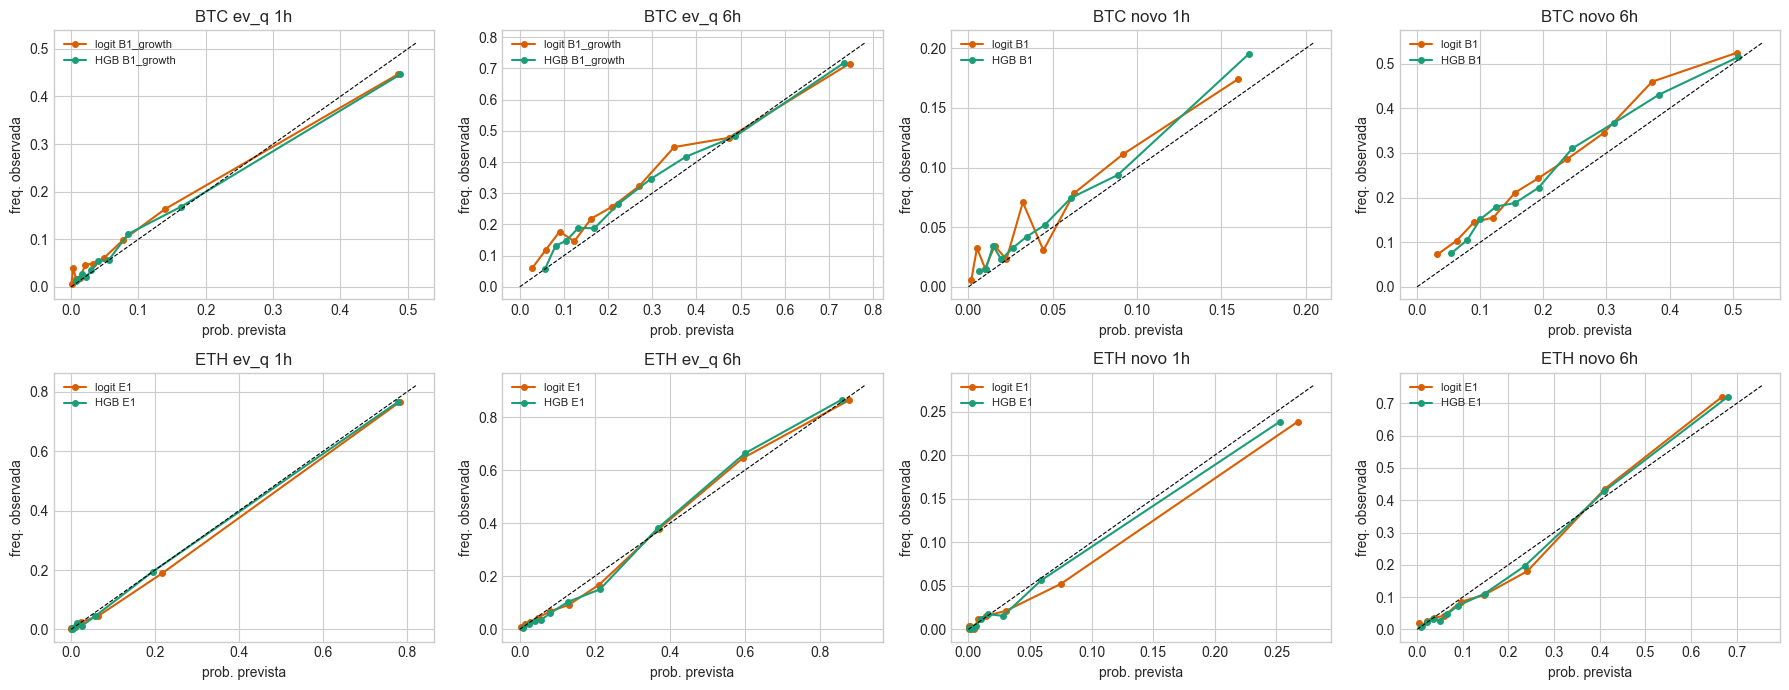

In [9]:
escolha_clas = {}
for (asset, tipo, h), P in preds_clas.items():
    g = grupos_usados[(asset, tipo, h)]
    y = P["y"].to_numpy(float)
    br = {n: float(np.mean((P[f"p_{n}"].to_numpy(float) - y) ** 2)) for n in g}
    melhor = min(br.values())
    cand = [n for n in g if br[n] <= melhor * 1.01]
    escolha_clas[(asset, tipo, h)] = min(cand, key=lambda n: len(g[n]))
sel = pd.DataFrame([{"rede": a.upper(), "alvo": t, "h": h, "modelo_selecionado": m, "n_variáveis": len(grupos_usados[(a, t, h)][m])}
                    for (a, t, h), m in escolha_clas.items()])
print("Modelo logístico selecionado (menos variáveis a até 1% do melhor Brier):")
display(sel)

linhas = []
for (asset, tipo, h), nome in escolha_clas.items():
    P = preds_clas[(asset, tipo, h)]
    for k, gk in P.groupby("fold"):
        y = gk["y"].to_numpy(float); b0 = np.mean((gk["p_B0"].to_numpy(float) - y) ** 2)
        base_nome = grupos_clas(asset)[0].__iter__().__next__()
        linhas.append({"rede": asset.upper(), "alvo": tipo, "h": h, "fold": k, "n": len(gk), "prevalencia": y.mean(),
                       "BSS_selecionado": 1 - np.mean((gk[f"p_{nome}"].to_numpy(float) - y) ** 2) / b0 if b0 > 0 else np.nan})
fold_tab = pd.DataFrame(linhas)
print("\nSkill de Brier do modelo selecionado, por fold (estabilidade):")
display(fold_tab.pivot_table(index=["rede", "alvo", "h"], columns="fold", values="BSS_selecionado").round(3))

fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharex=False, sharey=False)
for ax, ((asset, tipo, h), nome) in zip(axes.ravel(), escolha_clas.items()):
    P = preds_clas[(asset, tipo, h)]
    y = P["y"].to_numpy(float)
    for col, cor, rot in ((f"p_{nome}", "#d95f02", f"logit {nome}"), (f"p_HGB_{nome}", "#1b9e77", f"HGB {nome}")):
        if col not in P:
            continue
        p = P[col].to_numpy(float)
        bins = np.unique(np.quantile(p, np.linspace(0, 1, 11)))
        cat = np.clip(np.digitize(p, bins[1:-1]), 0, max(len(bins) - 2, 0))
        xs = [p[cat == c].mean() for c in np.unique(cat)]; ys = [y[cat == c].mean() for c in np.unique(cat)]
        ax.plot(xs, ys, "o-", color=cor, ms=4, label=rot)
    lim_max = max(ax.get_xlim()[1], ax.get_ylim()[1]); ax.plot([0, lim_max], [0, lim_max], "k--", lw=0.8)
    ax.set_title(f"{asset.upper()} {tipo} {h}h"); ax.set_xlabel("prob. prevista"); ax.set_ylabel("freq. observada"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(PASTA_SAIDA / "calibracao_classificadores.png", dpi=150, bbox_inches="tight"); plt.show()

## 7. Transmissão mercado ↔ rede

### 7.1 Granger bidirecional (HAC), todos os pares e lags, Holm global

Séries estacionárias: **diferenças horárias** do log de mempool e do log das taxas; log da RV em nível (já estacionária). Controle de sazonalidade (hora do dia). Wald com Newey–West. Os pares do texto do 08 (volatilidade ↔ taxa) agora estão incluídos. **Precedência estatística não é causalidade.**

In [10]:
def serie_d(df, col):
    return np.log(df[col].clip(lower=0.01)).diff(1).to_numpy(float)

series = {
    "btc": {"RV": dev["btc_lrv"].to_numpy(float), "mempool": serie_d(dev, "btc_mempool_vblocks"),
            "taxa p10": serie_d(dev, "btc_bq_taxa_p10_sat_vb"), "taxa p50": serie_d(dev, "btc_bq_taxa_p50_sat_vb")},
    "eth": {"RV": dev["eth_lrv"].to_numpy(float), "base fee": serie_d(dev, "eth_bq_base_fee_media_gwei")},
}
ctrl = dev[["cal_sin", "cal_cos"]].to_numpy(float)

def granger_wald(y, x, p, L=24):
    n = len(y); Y = y[p:]
    Z = np.column_stack([y[p - i: n - i] for i in range(1, p + 1)] + [x[p - i: n - i] for i in range(1, p + 1)] + [ctrl[p:]])
    ok = np.isfinite(Y) & np.isfinite(Z).all(axis=1)
    beta, V = ols_hac(Y[ok], Z[ok], L)
    idx = list(range(1 + p, 1 + 2 * p))
    W, pv = wald(beta, V, idx)
    return W, pv, float(beta[idx].sum()), int(ok.sum())

pares_granger = {"btc": [("RV", "mempool"), ("mempool", "RV"), ("RV", "taxa p10"), ("taxa p10", "RV"), ("RV", "taxa p50"), ("taxa p50", "RV"),
                         ("mempool", "taxa p10"), ("taxa p10", "mempool")],
                 "eth": [("RV", "base fee"), ("base fee", "RV")]}
linhas = []
for asset, pares in pares_granger.items():
    for x_nome, y_nome in pares:
        for lag in (1, 2, 4):
            W, pv, soma, n_ = granger_wald(series[asset][y_nome], series[asset][x_nome], lag)
            linhas.append({"rede": asset.upper(), "direção": f"{x_nome} -> {y_nome}", "lag": lag, "Wald_chi2": W, "p_valor": pv, "soma_coef_x": soma, "n": n_})
gr = pd.DataFrame(linhas)
gr["p_Holm"] = holm(gr["p_valor"].to_numpy())
gr["significativo"] = gr["p_Holm"] < 0.05
print("Granger (Wald HAC; p_Holm corrige todos os testes juntos):")
display(gr.round(5))

print("\nPares bidirecionais (significativos nos dois sentidos, mesmo lag, após Holm):")
bid = []
for asset, pares in pares_granger.items():
    vistos = set()
    for x_nome, y_nome in pares:
        chave = tuple(sorted([x_nome, y_nome]))
        if chave in vistos:
            continue
        vistos.add(chave)
        for lag in (1, 2, 4):
            a = gr[(gr["rede"] == asset.upper()) & (gr["direção"] == f"{x_nome} -> {y_nome}") & (gr["lag"] == lag)]["significativo"].iloc[0]
            b = gr[(gr["rede"] == asset.upper()) & (gr["direção"] == f"{y_nome} -> {x_nome}") & (gr["lag"] == lag)]["significativo"].iloc[0]
            bid.append({"rede": asset.upper(), "par": f"{chave[0]} <-> {chave[1]}", "lag": lag, "ida": bool(a), "volta": bool(b), "bidirecional": bool(a and b)})
bid = pd.DataFrame(bid)
display(bid.pivot_table(index=["rede", "par"], columns="lag", values="bidirecional", aggfunc="first"))

Granger (Wald HAC; p_Holm corrige todos os testes juntos):


,rede,direção,lag,Wald_chi2,p_valor,soma_coef_x,n,p_Holm,significativo
0,BTC,RV -> mempool,1,20.34426,0.00001,0.02411,14614,0.00010,True
1,BTC,RV -> mempool,2,24.58328,0.00000,0.02621,14613,0.00008,True
2,BTC,RV -> mempool,4,32.37357,0.00000,0.02703,14611,0.00003,True
3,BTC,mempool -> RV,1,0.00125,0.97181,0.00023,14614,1.00000,False
4,BTC,mempool -> RV,2,1.32376,0.51588,0.00704,14613,1.00000,False
5,BTC,mempool -> RV,4,5.80848,0.21391,-0.01891,14611,1.00000,False
6,BTC,RV -> taxa p10,1,15.43756,0.00009,0.02644,14614,0.00094,True
7,BTC,RV -> taxa p10,2,19.22200,0.00007,0.03043,14613,0.00080,True
8,BTC,RV -> taxa p10,4,28.99786,0.00001,0.02997,14611,0.00011,True
9,BTC,taxa p10 -> RV,1,1.01067,0.31474,-0.00480,14614,1.00000,False



Pares bidirecionais (significativos nos dois sentidos, mesmo lag, após Holm):


lag                            1      2      4
rede par                                      
BTC  RV <-> mempool        False  False  False
     RV <-> taxa p10       False  False  False
     RV <-> taxa p50       False  False  False
     mempool <-> taxa p10   True   True   True
ETH  RV <-> base fee        True   True   True

### 7.2 Estudo de evento: top-N explosões de RV, desclusterizado, com placebo pareado

Eventos: as **N maiores** horas de RV, separadas por ao menos 24 h. Para cada variável de resultado, mede-se a variação em log relativa à média 13–24 h antes (elimina diferenças de nível). O **placebo** sorteia, para cada evento, uma hora aleatória **com a mesma hora do dia**, fora da vizinhança de qualquer evento; a banda cinza é o intervalo de 95% do que ocorreria por acaso.

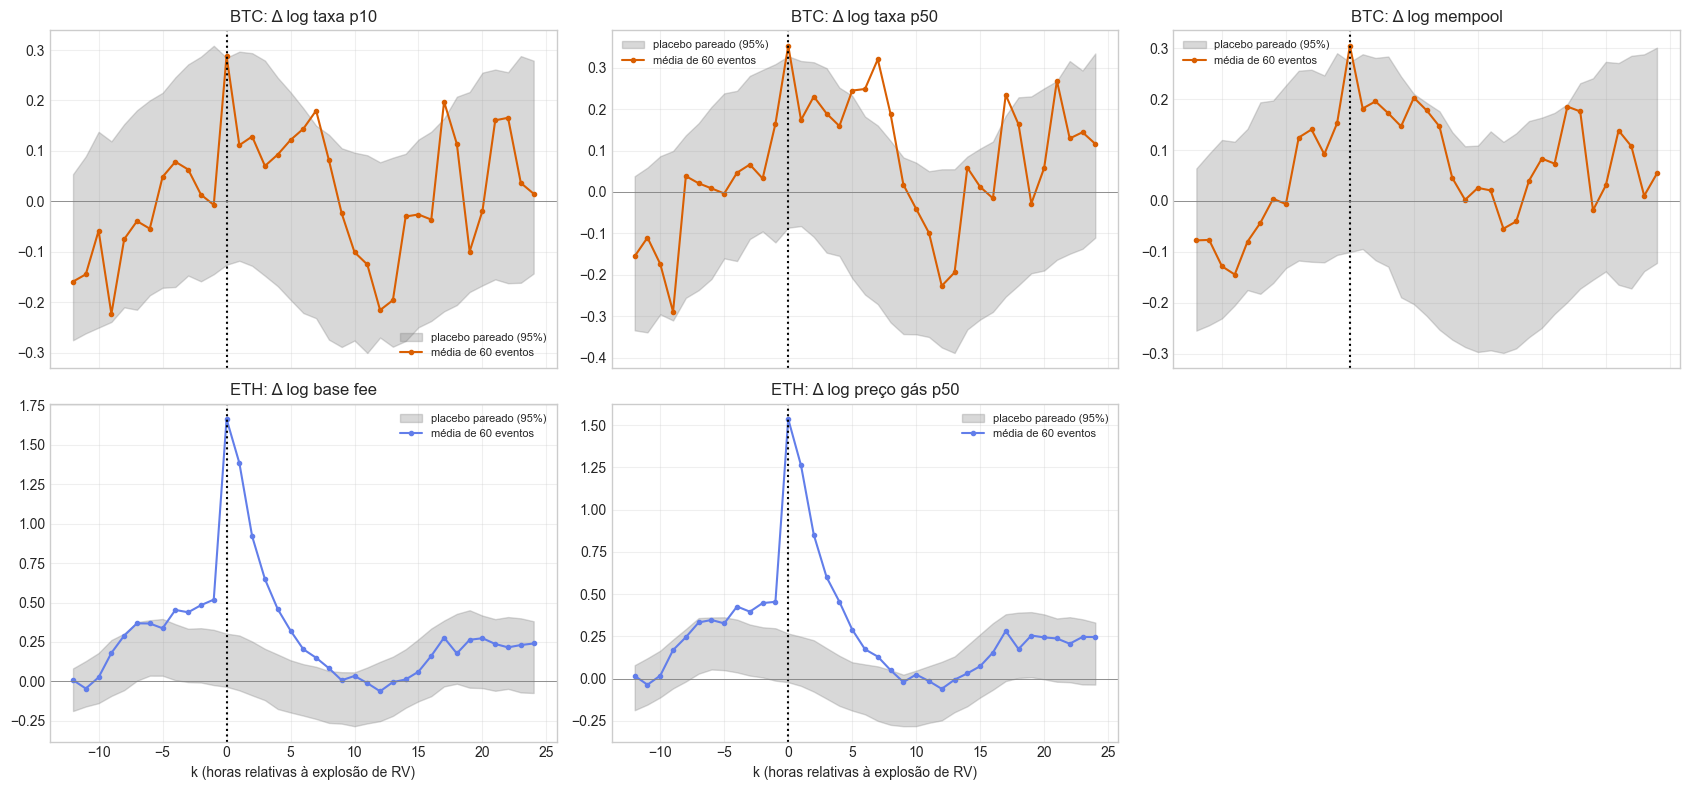

Quando o resultado sai da banda do placebo (k<0 = antes da explosão de RV; k>0 = depois):


,rede,variável,N_eventos,k fora da banda (antes),k fora da banda (depois),Δ médio em k=+1,Δ médio em k=+6
0,BTC,log taxa p10,60,[],"[7, 17]",0.111,0.144
1,BTC,log taxa p50,60,[],"[5, 6, 7, 8, 17, 21]",0.174,0.249
2,BTC,log mempool,60,[],[],0.181,0.178
3,ETH,log base fee,60,"[-4, -3, -2, -1]","[1, 2, 3, 4, 5, 6, 7, 8]",1.385,0.204
4,ETH,log preço gás p50,60,"[-4, -3, -2, -1]","[1, 2, 3, 4, 5, 6, 7]",1.261,0.174


In [11]:
def selecionar_eventos(score, n_ev, sep, margem_ini, margem_fim):
    s = np.asarray(score, float).copy(); s[~np.isfinite(s)] = -np.inf
    s[:margem_ini] = -np.inf; s[len(s) - margem_fim:] = -np.inf
    esc = []
    for i in np.argsort(-s):
        if not np.isfinite(s[i]) or len(esc) >= n_ev:
            break
        if all(abs(i - j) >= sep for j in esc):
            esc.append(int(i))
    return np.array(esc)

K = np.arange(-12, 25)
def matriz_curvas(serie):
    x = np.asarray(serie, float); n = len(x)
    C = np.full((n, len(K)), np.nan)
    for j, k in enumerate(K):
        idx = np.arange(n) + k; ok = (idx >= 0) & (idx < n); C[ok, j] = x[idx[ok]]
    base = pd.Series(x).shift(13).rolling(12, min_periods=8).mean().to_numpy()
    return C - base[:, None]

hora_dia = dev["hora"].dt.hour.to_numpy()
resultados_ev = {"btc": {"log taxa p10": log_pos(dev["btc_bq_taxa_p10_sat_vb"]), "log taxa p50": log_pos(dev["btc_bq_taxa_p50_sat_vb"]),
                         "log mempool": np.log(dev["btc_mempool_vblocks"].clip(lower=0.01))},
                 "eth": {"log base fee": log_pos(dev["eth_bq_base_fee_media_gwei"]), "log preço gás p50": log_pos(dev["eth_bq_preco_gas_p50_gwei"])}}
fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharex=True)
linhas_fora, painel = [], 0
for asset, outs in resultados_ev.items():
    ev = selecionar_eventos(dev[f"{asset}_lrv"], N_EVENTOS, 24, 24, 30)
    proib = np.zeros(len(dev), bool)
    for e in ev:
        proib[max(0, e - 24): e + 25] = True
    pool = {h: np.where((hora_dia == h) & ~proib)[0] for h in range(24)}
    pool = {h: v[(v >= 24) & (v < len(dev) - 30)] for h, v in pool.items()}
    for nome, serie in outs.items():
        C = matriz_curvas(serie)
        media_ev = np.nanmean(C[ev], axis=0)
        sim = np.empty((B_PERM, len(K)))
        for b in range(B_PERM):
            sim[b] = np.nanmean(C[np.array([rng.choice(pool[hora_dia[e]]) for e in ev])], axis=0)
        lo, hi = np.percentile(sim, [2.5, 97.5], axis=0)
        ax = axes.ravel()[painel]; painel += 1
        ax.fill_between(K, lo, hi, color="gray", alpha=0.3, label="placebo pareado (95%)")
        ax.plot(K, media_ev, "o-", ms=3, color="#d95f02" if asset == "btc" else "#627EEA", label=f"média de {len(ev)} eventos")
        ax.axvline(0, color="k", ls=":"); ax.axhline(0, color="gray", lw=0.6)
        ax.set_title(f"{asset.upper()}: Δ {nome}"); ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
        fora_k = [int(k) for k, m, l_, h_ in zip(K, media_ev, lo, hi) if (m > h_ or m < l_)]
        pre = [k for k in fora_k if k < 0]; pos_ = [k for k in fora_k if k > 0]
        linhas_fora.append({"rede": asset.upper(), "variável": nome, "N_eventos": len(ev), "k fora da banda (antes)": pre,
                            "k fora da banda (depois)": pos_, "Δ médio em k=+1": float(media_ev[list(K).index(1)]),
                            "Δ médio em k=+6": float(media_ev[list(K).index(6)])})
for ax in axes.ravel()[painel:]:
    ax.axis("off")
for ax in axes[1]:
    ax.set_xlabel("k (horas relativas à explosão de RV)")
plt.tight_layout(); plt.savefig(PASTA_SAIDA / "estudo_evento_pareado.png", dpi=150, bbox_inches="tight"); plt.show()
ev_tab = pd.DataFrame(linhas_fora)
print("Quando o resultado sai da banda do placebo (k<0 = antes da explosão de RV; k>0 = depois):")
display(ev_tab.round(3))

## 8. Faixa de custo em 6 h com calibração conforme (CQR)

Modelo quantílico (`GradientBoostingRegressor`, quantis 10%/50%/90%) para `Δ = ln(custo em t+6) − ln(custo em t)`, ancorado no custo atual. Como a cobertura bruta fica abaixo do nominal, aplica-se **calibração conforme** (*conformalized quantile regression*): os últimos 20% de cada janela de treino (com lacuna de 6 h para não sobrepor rótulos) estimam o ajuste `q̂` do intervalo `[q10 − q̂, q90 + q̂]`.

Avaliação: cobertura total e **por cauda** (abaixo de q10 deve ser ~10% e acima de q90 ~10%), cobertura por *fold*, IC por *bootstrap* em blocos, e perda *pinball* contra o benchmark ingênuo (quantis incondicionais de treino) com teste DM-HAC.

In [12]:
def pinball(y, pred, q):
    e = y - pred
    return np.maximum(q * e, (q - 1) * e)

def rodar_quantis(asset, col_custo, cols):
    lc = log_pos(dev[col_custo])
    d_q = dev.assign(delta=lc.shift(-H_PRAZO) - lc, lc_atual=lc)
    regs = []
    for k, f in enumerate(folds):
        tr = d_q.iloc[f["tr_ini"]:f["tr_fim"]].dropna(subset=cols + ["delta"])
        te = d_q.iloc[f["te_ini"]:f["te_fim"]].dropna(subset=cols + ["delta"])
        if len(tr) < 800 or len(te) == 0:
            continue
        cut = int(len(tr) * 0.8)
        fit, cal = tr.iloc[:cut], tr.iloc[cut + H_PRAZO:]
        Xf, yf = fit[cols].to_numpy(float), fit["delta"].to_numpy(float)
        mods = {q: GradientBoostingRegressor(loss="quantile", alpha=q, n_estimators=60, max_depth=3, random_state=SEMENTE).fit(Xf, yf) for q in (0.1, 0.5, 0.9)}
        sc = np.maximum(mods[0.1].predict(cal[cols].to_numpy(float)) - cal["delta"].to_numpy(float),
                        cal["delta"].to_numpy(float) - mods[0.9].predict(cal[cols].to_numpy(float)))
        n_c = len(sc); k_idx = int(np.ceil((n_c + 1) * COBERTURA_NOMINAL)); qhat = float(np.sort(sc)[min(k_idx, n_c) - 1])
        Xt = te[cols].to_numpy(float)
        nq = np.quantile(tr["delta"].to_numpy(float), [0.1, 0.5, 0.9])
        regs.append(pd.DataFrame({"pos": te.index.to_numpy(), "hora": te["hora"].to_numpy(), "fold": k + 1, "lc_atual": te["lc_atual"].to_numpy(float),
                                  "y": te["delta"].to_numpy(float), "q10": mods[0.1].predict(Xt), "q50": mods[0.5].predict(Xt), "q90": mods[0.9].predict(Xt),
                                  "qhat": qhat, "n10": nq[0], "n50": nq[1], "n90": nq[2]}))
    return pd.concat(regs, ignore_index=True)

def avaliar_quantis(Q, rotulo):
    y = Q["y"].to_numpy(float)
    lo_b, hi_b = Q["q10"].to_numpy(float), Q["q90"].to_numpy(float)
    lo_c, hi_c = lo_b - Q["qhat"].to_numpy(float), hi_b + Q["qhat"].to_numpy(float)
    idx = blocos_idx(len(y), B_BOOT)
    def cobertura(lo, hi):
        c = ((y >= lo) & (y <= hi)).astype(float)
        cb = c[idx].mean(axis=1)
        return float(c.mean()), float(np.percentile(cb, 2.5)), float(np.percentile(cb, 97.5))
    out = []
    for nome, lo, hi in (("bruta", lo_b, hi_b), ("conforme (CQR)", lo_c, hi_c)):
        cob, ci_lo, ci_hi = cobertura(lo, hi)
        out.append({"custo": rotulo, "faixa": nome, "cobertura": cob, "IC95_inf": ci_lo, "IC95_sup": ci_hi,
                    "nominal_dentro_do_IC": bool(ci_lo <= COBERTURA_NOMINAL <= ci_hi),
                    "abaixo_do_piso_%": float(np.mean(y < lo) * 100), "acima_do_teto_%": float(np.mean(y > hi) * 100),
                    "largura_log_media": float(np.mean(hi - lo)), "fator_largura": float(np.exp(np.mean(hi - lo)))})
    pin = []
    for q, col, ncol in ((0.1, "q10", "n10"), (0.5, "q50", "n50"), (0.9, "q90", "n90")):
        lm = pinball(y, Q[col].to_numpy(float), q); ln = pinball(y, Q[ncol].to_numpy(float), q)
        m, se = hac_media(ln - lm, 24 + H_PRAZO)
        pin.append({"custo": rotulo, "quantil": q, "pinball_modelo": float(lm.mean()), "pinball_naive": float(ln.mean()),
                    "ganho_%": 100 * (1 - float(lm.mean()) / float(ln.mean())), "DM_t": m / se, "p_DM_unicaudal": float(stats.norm.sf(m / se))})
    return pd.DataFrame(out), pd.DataFrame(pin)

cols_q_btc = grupos_clas("btc")[0]["B1_growth"]
cols_q_eth = grupos_clas("eth")[0]["E1"]
Q_btc = rodar_quantis("btc", "btc_bloco_fee_min_mediana" if dev["btc_bloco_fee_min_mediana"].notna().mean() > 0.5 else "btc_bq_taxa_p10_sat_vb", cols_q_btc)
custo_q_btc = "fee_min por bloco" if dev["btc_bloco_fee_min_mediana"].notna().mean() > 0.5 else "p10 horário"
Q_eth = rodar_quantis("eth", "eth_bq_preco_gas_p10_gwei", cols_q_eth)
cob_btc, pin_btc = avaliar_quantis(Q_btc, f"BTC ({custo_q_btc})")
cob_eth, pin_eth = avaliar_quantis(Q_eth, "ETH (p10 do preço de gás)")
cob_tab = pd.concat([cob_btc, cob_eth], ignore_index=True)
pin_tab = pd.concat([pin_btc, pin_eth], ignore_index=True)
print("COBERTURA da faixa [q10, q90] (nominal 80%), IC95% por bootstrap em blocos:")
display(cob_tab.round(4))
print("\nPERDA PINBALL: modelo vs. benchmark ingênuo (DM-HAC unicaudal):")
display(pin_tab.round(4))
cob_fold = pd.concat([Q_btc.assign(custo="BTC"), Q_eth.assign(custo="ETH")]).assign(
    cob_bruta=lambda d: ((d["y"] >= d["q10"]) & (d["y"] <= d["q90"])).astype(float),
    cob_cqr=lambda d: ((d["y"] >= d["q10"] - d["qhat"]) & (d["y"] <= d["q90"] + d["qhat"])).astype(float))
print("\nCobertura por fold:")
display(cob_fold.pivot_table(index="custo", columns="fold", values=["cob_bruta", "cob_cqr"], aggfunc="mean").round(3))

COBERTURA da faixa [q10, q90] (nominal 80%), IC95% por bootstrap em blocos:


,custo,faixa,cobertura,IC95_inf,IC95_sup,nominal_dentro_do_IC,abaixo_do_piso_%,acima_do_teto_%,largura_log_media,fator_largura
0,BTC (fee_min por bloco),bruta,0.5419,0.5099,0.5748,False,23.6958,22.1161,1.7182,5.5744
1,BTC (fee_min por bloco),conforme (CQR),0.7663,0.7395,0.7967,False,11.8663,11.4989,2.9720,19.5302
2,ETH (p10 do preço de gás),bruta,0.8092,0.7903,0.8281,True,8.2465,10.8333,1.1718,3.2277
3,ETH (p10 do preço de gás),conforme (CQR),0.8285,0.8077,0.8481,False,7.0486,10.1042,1.2060,3.3400



PERDA PINBALL: modelo vs. benchmark ingênuo (DM-HAC unicaudal):


,custo,quantil,pinball_modelo,pinball_naive,ganho_%,DM_t,p_DM_unicaudal
0,BTC (fee_min por bloco),0.1,0.2426,0.2917,16.8359,10.8864,0.0000
1,BTC (fee_min por bloco),0.5,0.4787,0.4893,2.1532,1.6507,0.0494
2,BTC (fee_min por bloco),0.9,0.2643,0.2914,9.3041,5.2794,0.0000
3,ETH (p10 do preço de gás),0.1,0.0766,0.1584,51.6282,17.8950,0.0000
4,ETH (p10 do preço de gás),0.5,0.1803,0.2886,37.5330,14.5895,0.0000
5,ETH (p10 do preço de gás),0.9,0.1046,0.1600,34.6235,16.5285,0.0000



Cobertura por fold:


cob_bruta                                                  cob_cqr                                                 
fold          1      2      3      4      5      6      7      8       1      2      3      4      5      6      7      8
custo                                                                                                                    
BTC       0.518  0.440  0.526  0.577  0.713  1.000  1.000  1.000   0.693  0.719  0.798  0.782  0.884  1.000  1.000  1.000
ETH       0.744  0.839  0.824  0.829  0.761  0.814  0.831  0.832   0.886  0.878  0.869  0.814  0.721  0.808  0.821  0.831

## 9. Política de espera: enviar agora ou esperar até o prazo (6 h)?

Decisão a cada hora: **executar em `t+1`** (agora) ou **esperar até `t+6`** quando o modelo prevê as quedas mais fortes de custo (5%, 10% ou 20% das horas; limiar fixado só no treino de cada *fold*).

**Correções em relação ao 08**
- Custo em **USD por transação** com o **preço real** do ativo em cada hora (BTC: 140 vB; ETH: 21.000 de gás).
- **Economia agregada** `1 − Σ custo(política) / Σ custo(agora)` com IC por *bootstrap* em blocos (evita médias de razões explosivas) e **custo-base em USD** para dar escala.
- **Economia condicional** por transação em espera e **custo de espera**: a política espera até 5 horas, então calcula-se a economia **líquida** quando cada hora esperada custa uma fração κ do custo de referência, com o **κ de equilíbrio**.
- **Três proxies de custo no BTC** (p10, p50 e `fee_min` por bloco) e dois no ETH (p10 e p50 do preço de gás).
- **Modelos:** o do estado da taxa, o selecionado pela regra de parcimônia e o B3 completo (para comparar com o 08).
- **Segmentos ex-ante** (só informação em `t`) e por trimestre real, com número de horas e IC. Nada de definir regime pelo custo realizado.

In [13]:
def usd_btc(taxa, preco): return taxa * 140.0 * 1e-8 * preco
def usd_eth(gwei, preco): return gwei * 21000.0 * 1e-9 * preco

COSTS = {"btc": {"fee_min": ("btc_bloco_fee_min_mediana", usd_btc), "p10": ("btc_bq_taxa_p10_sat_vb", usd_btc), "p50": ("btc_bq_taxa_p50_sat_vb", usd_btc)},
         "eth": {"p10": ("eth_bq_preco_gas_p10_gwei", usd_eth), "p50": ("eth_bq_preco_gas_p50_gwei", usd_eth)}}
MODELOS_POL = {"btc": ["B1", "B1_growth", "B3"], "eth": ["E1", "E2"]}
BASE_POL = {"btc": "B1", "eth": "E1"}

def rodar_politica(asset, proxy):
    col, usd_fn = COSTS[asset][proxy]
    c = dev[col].astype(float)
    if c.notna().mean() < 0.5:
        return None
    lc = log_pos(c)
    d_op = dev.assign(delta=lc.shift(-H_PRAZO) - lc.shift(-1))
    g = grupos_clas(asset)[0]
    modelos = MODELOS_POL[asset]
    todas = sorted(set(sum([g[m] for m in modelos], [])))
    regs = []
    for k, f in enumerate(folds):
        tr = d_op.iloc[f["tr_ini"]:f["tr_fim"]].dropna(subset=todas + ["delta"])
        te = d_op.iloc[f["te_ini"]:f["te_fim"]].dropna(subset=todas + ["delta"])
        if len(tr) < 500 or len(te) == 0:
            continue
        ytr = tr["delta"].to_numpy(float)
        reg = {"pos": te.index.to_numpy(), "fold": k + 1, "y": te["delta"].to_numpy(float)}
        for m in modelos:
            b = ols_fit(tr[g[m]].to_numpy(float), ytr)
            reg[f"d_{m}"] = ols_pred(b, te[g[m]].to_numpy(float))
            p_in = ols_pred(b, tr[g[m]].to_numpy(float))
            for r in TAXAS_ESPERA:
                reg[f"tau_{m}_{r:.2f}"] = np.full(len(te), np.quantile(p_in, r))
        regs.append(pd.DataFrame(reg))
    P = pd.concat(regs, ignore_index=True)
    pos = P["pos"].to_numpy(int); n = len(dev)
    carr = c.to_numpy(float); preco = dev[f"{asset}_fechamento"].to_numpy(float)
    ref_raw = c.rolling(168, min_periods=84).median().to_numpy(float)
    U = np.full((len(pos), H_PRAZO), np.nan)
    for k in range(1, H_PRAZO + 1):
        ok = pos + k < n
        U[ok, k - 1] = usd_fn(carr[pos[ok] + k], preco[pos[ok] + k])
    ref_usd = usd_fn(ref_raw[pos], preco[pos])
    valido = np.isfinite(U).all(axis=1) & np.isfinite(ref_usd) & (ref_usd > 0)
    P = P.loc[valido].reset_index(drop=True); U = U[valido]; ref_usd = ref_usd[valido]
    pos_v = pos[valido]
    return {"P": P, "U": U, "ref": ref_usd, "pos": pos_v, "idx": blocos_idx(len(P), B_BOOT), "modelos": modelos}

def avaliar_politica(R, m, rate):
    P, U, ref, idx = R["P"], R["U"], R["ref"], R["idx"]
    espera = P[f"d_{m}"].to_numpy(float) <= P[f"tau_{m}_{rate:.2f}"].to_numpy(float)
    agora, prazo = U[:, 0], U[:, -1]
    mod = np.where(espera, prazo, agora)
    econ = agora - mod
    tot_ag = agora.sum()
    agg = 100 * econ.sum() / tot_ag
    agg_b = 100 * econ[idx].sum(axis=1) / agora[idx].sum(axis=1)
    custo_espera_ref = float((espera * (H_PRAZO - 1) * ref).sum())
    kappa_eq = float(econ.sum() / custo_espera_ref) if custo_espera_ref > 0 else np.nan
    return {"n": len(agora), "espera_%": 100 * espera.mean(), "custo_base_USD_10k": float(agora.mean() * 10000),
            "economia_USD_10k": float(econ.mean() * 10000), "economia_agregada_%": float(agg),
            "IC95_inf": float(np.percentile(agg_b, 2.5)), "IC95_sup": float(np.percentile(agg_b, 97.5)),
            "econ_cond_USD_por_tx_em_espera": float(econ[espera].mean()) if espera.any() else np.nan,
            "kappa_equilibrio": kappa_eq, "economia_oraculo_%": float(100 * (agora - U.min(axis=1)).sum() / tot_ag)}, espera, agg_b

linhas_pol, resultados_pol = [], {}
for asset in ("btc", "eth"):
    for proxy in COSTS[asset]:
        R = rodar_politica(asset, proxy)
        if R is None:
            print(f"[{asset.upper()} {proxy}] cobertura insuficiente da série de custo; pulado"); continue
        resultados_pol[(asset, proxy)] = R
        base_ref = {}
        for m in R["modelos"]:
            y = R["P"]["y"].to_numpy(float); e = y - R["P"][f"d_{m}"].to_numpy(float)
            for rate in TAXAS_ESPERA:
                met, esp, agg_b = avaliar_politica(R, m, rate)
                base_ref[(m, rate)] = agg_b
                linhas_pol.append({"rede": asset.upper(), "proxy": proxy, "modelo": m, "taxa_espera": rate, "MSE_delta": float(np.mean(e ** 2)), **met})
pol = pd.DataFrame(linhas_pol)

# diferença do modelo vs. modelo de estado (IC direto)
dif = []
for (asset, proxy), R in resultados_pol.items():
    for m in R["modelos"]:
        if m == BASE_POL[asset]:
            continue
        for rate in TAXAS_ESPERA:
            _, _, a_m = avaliar_politica(R, m, rate); _, _, a_b = avaliar_politica(R, BASE_POL[asset], rate)
            d_b = a_m - a_b
            dif.append({"rede": asset.upper(), "proxy": proxy, "modelo": m, "vs": BASE_POL[asset], "taxa_espera": rate,
                        "dif_economia_pp": float(np.mean(d_b)), "IC95_inf": float(np.percentile(d_b, 2.5)), "IC95_sup": float(np.percentile(d_b, 97.5))})
dif_tab = pd.DataFrame(dif)
print("POLÍTICA — economia agregada (% do gasto de 'agora'), com IC, escala em USD por 10.000 transações:")
display(pol.drop(columns=["MSE_delta"]).round(4))
print("\nDiferença de economia do modelo vs. modelo de estado da taxa (pontos percentuais), IC direto por bootstrap:")
display(dif_tab.round(4))

POLÍTICA — economia agregada (% do gasto de 'agora'), com IC, escala em USD por 10.000 transações:


,rede,proxy,modelo,taxa_espera,n,espera_%,custo_base_USD_10k,economia_USD_10k,economia_agregada_%,IC95_inf,IC95_sup,econ_cond_USD_por_tx_em_espera,kappa_equilibrio,economia_oraculo_%
0,BTC,fee_min,B1,0.05,2674,5.3104,577.8657,34.8123,6.0243,3.5639,8.1773,0.0656,0.4394,78.6837
1,BTC,fee_min,B1,0.10,2674,12.2663,577.8657,53.1603,9.1994,6.1432,11.4710,0.0433,0.3089,78.6837
2,BTC,fee_min,B1,0.20,2674,22.4009,577.8657,70.4355,12.1889,8.3598,14.9508,0.0314,0.2333,78.6837
3,BTC,fee_min,B1_growth,0.05,2674,5.4974,577.8657,35.8723,6.2077,3.6549,8.3639,0.0653,0.4237,78.6837
4,BTC,fee_min,B1_growth,0.10,2674,13.4256,577.8657,55.5595,9.6146,6.5384,12.0516,0.0414,0.2926,78.6837
5,BTC,fee_min,B1_growth,0.20,2674,24.3455,577.8657,71.8018,12.4253,8.5660,15.3595,0.0295,0.2179,78.6837
6,BTC,fee_min,B3,0.05,2674,5.5722,577.8657,33.3955,5.7791,3.2364,8.0427,0.0599,0.3945,78.6837
7,BTC,fee_min,B3,0.10,2674,12.1167,577.8657,52.1446,9.0237,5.7018,11.4058,0.0430,0.3017,78.6837
8,BTC,fee_min,B3,0.20,2674,23.2236,577.8657,73.1073,12.6513,8.8245,15.3329,0.0315,0.2323,78.6837
9,BTC,p10,B1,0.05,5760,5.9722,522.9711,51.3561,9.8201,7.1850,12.8940,0.0860,0.7221,58.5379



Diferença de economia do modelo vs. modelo de estado da taxa (pontos percentuais), IC direto por bootstrap:


,rede,proxy,modelo,vs,taxa_espera,dif_economia_pp,IC95_inf,IC95_sup
0,BTC,fee_min,B1_growth,B1,0.05,0.1684,-0.0432,0.4009
1,BTC,fee_min,B1_growth,B1,0.10,0.4626,-0.1903,1.2685
2,BTC,fee_min,B1_growth,B1,0.20,0.3172,-0.9614,1.3356
3,BTC,fee_min,B3,B1,0.05,-0.2493,-0.7187,0.2142
4,BTC,fee_min,B3,B1,0.10,-0.1934,-1.4520,0.8245
5,BTC,fee_min,B3,B1,0.20,0.5311,-0.7202,1.6605
6,BTC,p10,B1_growth,B1,0.05,0.1469,-0.0483,0.4893
7,BTC,p10,B1_growth,B1,0.10,-0.0025,-0.1075,0.1122
8,BTC,p10,B1_growth,B1,0.20,0.3497,-0.0134,0.7713
9,BTC,p10,B3,B1,0.05,0.5557,-0.5245,1.6067


### 9.1 Modelo da política, segmentos ex-ante, trimestres e custo do atraso

O modelo e o proxy "primários" da política são escolhidos **por regra**: proxy primário do BTC = `fee_min` (o mais próximo do preço marginal de inclusão), do ETH = p10 do preço de gás; modelo primário = o de menor MSE fora da amostra para `Δ`, **o mais simples a até 1% do melhor**; taxa de espera primária = 10% (fixada antes). Os segmentos usam apenas o que se sabe em `t` (a taxa já estar acima do P90 móvel).

In [14]:
PROXY_PRIMARIO = {"btc": "fee_min" if ("btc", "fee_min") in resultados_pol else "p10", "eth": "p10"}
TAXA_PRIMARIA = 0.10
escolha_pol = {}
for asset in ("btc", "eth"):
    sub = pol[(pol["rede"] == asset.upper()) & (pol["proxy"] == PROXY_PRIMARIO[asset]) & (pol["taxa_espera"] == TAXA_PRIMARIA)].set_index("modelo")["MSE_delta"]
    g = grupos_clas(asset)[0]
    cand = [m for m in sub.index if sub[m] <= sub.min() * 1.01]
    escolha_pol[asset] = min(cand, key=lambda m: len(g[m]))
print("Modelo primário da política:", {a.upper(): m for a, m in escolha_pol.items()}, "| proxies primários:", {a.upper(): p for a, p in PROXY_PRIMARIO.items()})

def agg_ic(econ, base, idx):
    a = 100 * econ.sum() / base.sum()
    b = 100 * econ[idx].sum(axis=1) / base[idx].sum(axis=1)
    return float(a), float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5))

linhas_seg, linhas_k = [], []
for asset in ("btc", "eth"):
    R = resultados_pol[(asset, PROXY_PRIMARIO[asset])]
    m = escolha_pol[asset]
    met, espera, _ = avaliar_politica(R, m, TAXA_PRIMARIA)
    U, ref, P = R["U"], R["ref"], R["P"]
    agora, prazo = U[:, 0], U[:, -1]
    econ = agora - np.where(espera, prazo, agora)
    pos = R["pos"]
    # segmentos ex-ante: estado da taxa em t
    em_ev = dev[f"{asset}_em_evento"].to_numpy(float)[pos]
    hora = pd.to_datetime(dev["hora"].iloc[pos].to_numpy(), utc=True)
    trimestre = np.array([f"{h.year}-T{h.quarter}" for h in hora])
    segmentos = [("estado em t", "taxa JÁ acima do P90 móvel", em_ev == 1), ("estado em t", "taxa abaixo do P90 móvel", em_ev == 0)]
    segmentos += [("trimestre real", t, trimestre == t) for t in sorted(set(trimestre))]
    for tipo_seg, nome, mask in segmentos:
        n_s = int(mask.sum())
        if n_s < 50:
            continue
        idx_s = blocos_idx(n_s, 300)
        a, lo, hi = agg_ic(econ[mask], agora[mask], idx_s)
        linhas_seg.append({"rede": asset.upper(), "modelo": m, "tipo": tipo_seg, "segmento": nome, "horas": n_s,
                           "espera_%": 100 * espera[mask].mean(), "economia_agregada_%": a, "IC95_inf": lo, "IC95_sup": hi,
                           "aviso": "amostra insuficiente" if n_s < MIN_HORAS_SEGMENTO else ""})
    # sensibilidade ao custo do atraso
    custo_atraso = (espera * (H_PRAZO - 1) * ref)
    for kappa in KAPPAS:
        liq = econ - kappa * custo_atraso
        idx_k = blocos_idx(len(liq), 300)
        a, lo, hi = agg_ic(liq, agora, idx_k)
        linhas_k.append({"rede": asset.upper(), "modelo": m, "kappa_(fração do custo de ref. por hora)": kappa, "economia_líquida_%": a, "IC95_inf": lo, "IC95_sup": hi})
seg_tab = pd.DataFrame(linhas_seg)
k_tab = pd.DataFrame(linhas_k)
print("Segmentos ex-ante e trimestres reais (modelo e proxy primários, espera = 10%):")
display(seg_tab.round(3))
print("\nSensibilidade ao custo do atraso (economia líquida; κ = custo de cada hora esperada, em fração do custo de referência):")
display(k_tab.round(3))

Modelo primário da política: {'BTC': 'B1', 'ETH': 'E1'} | proxies primários: {'BTC': 'fee_min', 'ETH': 'p10'}
Segmentos ex-ante e trimestres reais (modelo e proxy primários, espera = 10%):


,rede,modelo,tipo,segmento,horas,espera_%,economia_agregada_%,IC95_inf,IC95_sup,aviso
0,BTC,B1,estado em t,taxa JÁ acima do P90 móvel,243,86.831,40.723,32.491,48.854,amostra insuficiente
1,BTC,B1,estado em t,taxa abaixo do P90 móvel,2431,4.813,1.576,0.101,2.683,
2,BTC,B1,trimestre real,2025-T4,525,8.571,3.439,-0.353,7.215,
3,BTC,B1,trimestre real,2026-T1,1795,13.983,11.020,7.925,14.615,
4,BTC,B1,trimestre real,2026-T2,354,9.040,10.648,2.673,13.631,amostra insuficiente
5,ETH,E1,estado em t,taxa JÁ acima do P90 móvel,602,75.083,52.121,42.794,58.962,
6,ETH,E1,estado em t,taxa abaixo do P90 móvel,5158,4.459,3.315,2.427,4.423,
7,ETH,E1,trimestre real,2025-T4,672,8.482,8.721,5.220,13.880,
8,ETH,E1,trimestre real,2026-T1,2160,16.343,31.262,23.550,39.001,
9,ETH,E1,trimestre real,2026-T2,2184,10.668,24.333,17.759,31.349,



Sensibilidade ao custo do atraso (economia líquida; κ = custo de cada hora esperada, em fração do custo de referência):


,rede,modelo,kappa_(fração do custo de ref. por hora),economia_líquida_%,IC95_inf,IC95_sup
0,BTC,B1,0.00,9.199,6.345,11.678
1,BTC,B1,0.01,8.902,6.289,11.425
2,BTC,B1,0.02,8.604,5.512,11.028
3,BTC,B1,0.05,7.710,4.948,10.205
4,BTC,B1,0.10,6.221,3.548,8.566
5,ETH,E1,0.00,24.874,19.519,29.732
6,ETH,E1,0.01,24.478,18.990,27.740
7,ETH,E1,0.02,24.082,19.370,28.312
8,ETH,E1,0.05,22.892,17.506,26.708
9,ETH,E1,0.10,20.910,15.637,25.306


## 10. Síntese gerada por regras, figuras e especificação congelada

Todas as frases abaixo são montadas por regras aplicadas às tabelas calculadas. A especificação congelada (`especificacao_congelada.json`) é o que o notebook final usará para abrir o *holdout* **uma única vez**.

In [15]:
linhas = []
L = linhas.append
L("# Síntese gerada por regras (nenhuma frase fixa)\n")

# Poisson / espera
L(f"- **Blocos BTC:** λ = {lam:.3f}/h, dispersão = {disp:.3f} (p = {p_disp:.3f}); tempos entre blocos: D = {ks.statistic:.3f}, "
  f"P(espera>30 min) empírica = {p30_emp*100:.2f}% vs. {p30_teo*100:.2f}% teórica. Veredito: {veredito_poisson}.")

# EIP-1559 estrutural
mse_m0 = tab_struct.set_index("modelo").loc["M0", "MSE"]
r2 = tab_struct.set_index("modelo")["R2_oos_vs_M0"]
L(f"- **ETH, EIP-1559:** uso médio > 0,5 em {(r > 0.5).mean()*100:.1f}% das horas; R² fora da amostra de Δ ln(base fee, 1 h): "
  f"estrutural = {r2['M_estrutural']:.3f}, estrutural calibrado = {r2['M_estrutural_cal']:.3f}, modelo E1 = {r2['M_E1']:.3f}.")

# Classificação: fila (BTC)
btc_q = cw[(cw["rede"] == "BTC") & (cw["comparação"].str.startswith("B1 -> B1_"))]
conf = btc_q[btc_q["veredito"] == "ganho preditivo confirmado"]
sem_ganho = btc_q[btc_q["veredito"] == "informação detectável, sem ganho de acurácia"]
def lista(df):
    return "; ".join(f"{r['comparação'].split('B1_')[1]} ({r['alvo']} {r['h']}h: ΔBrier {r['dBrier_%']:+.2f}%)" for _, r in df.iterrows()) or "nenhuma"
L(f"- **BTC, fila (variável a variável):** ganho confirmado em: {lista(conf)}. Informação sem ganho de acurácia em: {lista(sem_ganho)}.")
b3 = cw[(cw["rede"] == "BTC") & (cw["comparação"] == "B1 -> B3")]
L("- **BTC, fila completa (B1 -> B3):** " + "; ".join(f"{r['alvo']} {r['h']}h: ΔBrier {r['dBrier_%']:+.2f}% [{r['veredito']}]" for _, r in b3.iterrows()) + ".")
mk = pd.concat([cw[(cw["rede"] == "BTC") & (cw["comparação"] == "B3 -> B4")], cw[(cw["rede"] == "ETH") & (cw["comparação"] == "E1 -> E2")]])
L("- **Mercado além do estado da taxa:** " + "; ".join(f"{r['rede']} {r['alvo']} {r['h']}h: ΔBrier {r['dBrier_%']:+.2f}% [{r['veredito']}]" for _, r in mk.iterrows()) + ".")
hg = cw[cw["aprox_arvore"] & (cw["rede"] == "BTC")]
L("- **Árvores (aproximação do CW):** " + "; ".join(f"{r['comparação']} {r['alvo']} {r['h']}h: ΔAP {r['dAP']:+.4f} [{r['veredito']}]" for _, r in hg.iterrows()) + ".")

# Granger
sig = gr[gr["significativo"]]
L(f"- **Granger (HAC, Holm global):** {len(sig)} de {len(gr)} testes significativos. Pares bidirecionais: "
  + ("; ".join(sorted({f"{r['rede']} {r['par']} (lag {r['lag']})" for _, r in bid[bid['bidirecional']].iterrows()})) or "nenhum") + ".")

# Evento
for _, r in ev_tab.iterrows():
    L(f"- **Evento ({r['rede']}, {r['variável']}):** fora da banda antes de t=0 em k={r['k fora da banda (antes)'] or 'nenhum'}; depois em k={r['k fora da banda (depois)'] or 'nenhum'}; "
      f"Δ médio em k=+1: {r['Δ médio em k=+1']:+.3f}.")

# Quantis
for _, r in cob_tab.iterrows():
    L(f"- **Faixa {r['custo']} ({r['faixa']}):** cobertura {r['cobertura']*100:.1f}% [IC95 {r['IC95_inf']*100:.1f}–{r['IC95_sup']*100:.1f}], "
      f"nominal {'DENTRO' if r['nominal_dentro_do_IC'] else 'FORA'} do IC; abaixo do piso {r['abaixo_do_piso_%']:.1f}%, acima do teto {r['acima_do_teto_%']:.1f}%; fator de largura {r['fator_largura']:.1f}x.")
for _, r in pin_tab.iterrows():
    L(f"- **Pinball {r['custo']} q{int(r['quantil']*100)}:** ganho de {r['ganho_%']:.1f}% sobre o benchmark ingênuo (DM p = {r['p_DM_unicaudal']:.3g}).")

# Política
for asset in ("btc", "eth"):
    m = escolha_pol[asset]
    r_ = pol[(pol["rede"] == asset.upper()) & (pol["proxy"] == PROXY_PRIMARIO[asset]) & (pol["modelo"] == m) & (pol["taxa_espera"] == TAXA_PRIMARIA)].iloc[0]
    sensivel = k_tab[(k_tab["rede"] == asset.upper())]
    kmax_pos = sensivel[sensivel["IC95_inf"] > 0]["kappa_(fração do custo de ref. por hora)"].max()
    L(f"- **Política {asset.upper()} ({PROXY_PRIMARIO[asset]}, modelo {m}, espera {r_['espera_%']:.1f}% das horas):** economia agregada {r_['economia_agregada_%']:.2f}% "
      f"[IC95 {r_['IC95_inf']:.2f}–{r_['IC95_sup']:.2f}]; custo-base US$ {r_['custo_base_USD_10k']:.2f} por 10.000 tx, economia US$ {r_['economia_USD_10k']:.2f}; "
      f"κ de equilíbrio = {r_['kappa_equilibrio']:.3f}; maior κ testado com economia líquida positiva (IC>0): {kmax_pos if pd.notna(kmax_pos) else 'nenhum'}; "
      f"limite do oráculo = {r_['economia_oraculo_%']:.1f}%.")
d_ = dif_tab[(dif_tab["taxa_espera"] == TAXA_PRIMARIA)]
for _, r in d_[d_["proxy"].isin(list(PROXY_PRIMARIO.values()))].iterrows():
    L(f"- **Política {r['rede']} {r['proxy']}: {r['modelo']} vs. {r['vs']}:** diferença {r['dif_economia_pp']:+.3f} p.p. [IC95 {r['IC95_inf']:+.3f}; {r['IC95_sup']:+.3f}] "
      f"({'distinguível de zero' if (r['IC95_inf'] > 0 or r['IC95_sup'] < 0) else 'IC inclui zero'}).")
sintese_md = "\n".join(linhas)
print(sintese_md)
(PASTA_SAIDA / "sintese_09.md").write_text(sintese_md, encoding="utf-8")

# Síntese gerada por regras (nenhuma frase fixa)

- **Blocos BTC:** λ = 6.033/h, dispersão = 1.002 (p = 0.413); tempos entre blocos: D = 0.005, P(espera>30 min) empírica = 4.87% vs. 4.90% teórica. Veredito: compatível com Poisson/exponencial (D pequeno e dispersão não rejeitada).
- **ETH, EIP-1559:** uso médio > 0,5 em 85.4% das horas; R² fora da amostra de Δ ln(base fee, 1 h): estrutural = -1.814, estrutural calibrado = 0.150, modelo E1 = 0.252.
- **BTC, fila (variável a variável):** ganho confirmado em: growth (ev_q 1h: ΔBrier +1.42%); conf (ev_q 1h: ΔBrier +0.15%); growth (ev_q 6h: ΔBrier +1.02%); growth (novo 6h: ΔBrier +0.71%). Informação sem ganho de acurácia em: rel30d (ev_q 1h: ΔBrier -3.10%).
- **BTC, fila completa (B1 -> B3):** ev_q 1h: ΔBrier -1.42% [informação detectável, sem ganho de acurácia]; ev_q 6h: ΔBrier -0.86% [informação detectável, sem ganho de acurácia]; novo 1h: ΔBrier -4.15% [sem efeito detectável]; novo 6h: ΔBrier -0.85% [sem efeito detectável].
- **Mercado al

5424

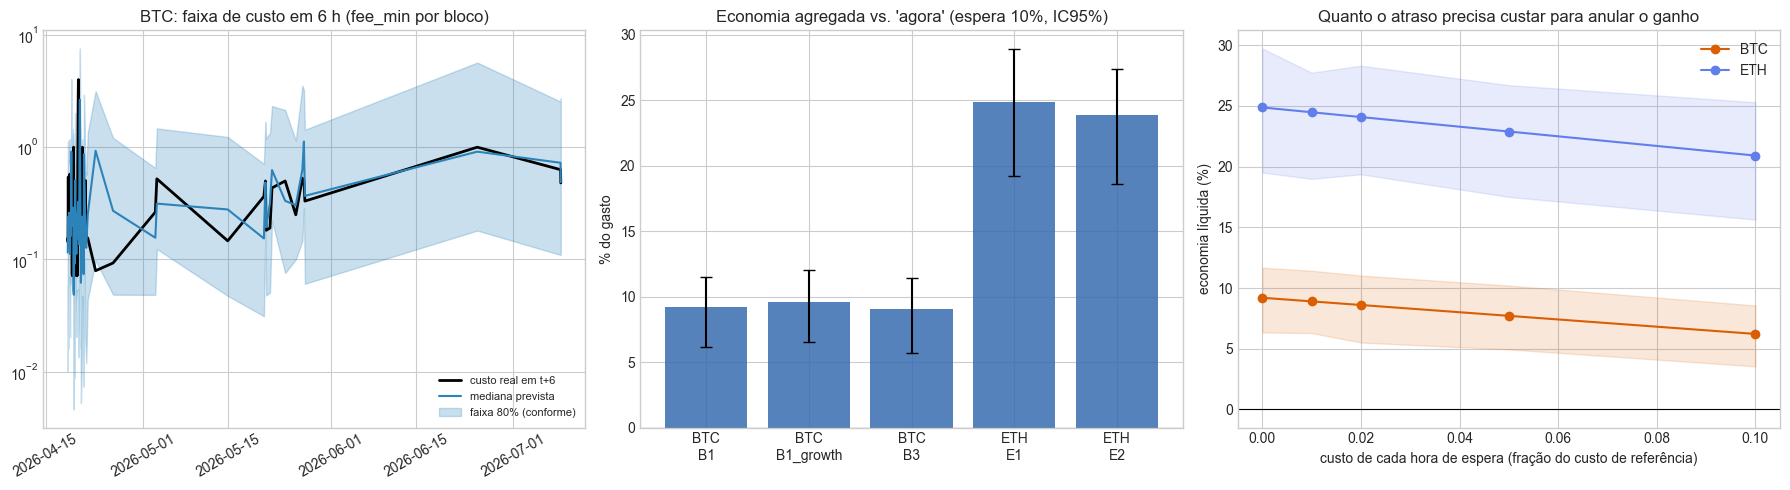


Arquivos exportados em: /home/alisson/datathon fgv/Análises/modelagem/09
Especificação congelada salva (holdout ainda FECHADO).


In [16]:
# ---------- figura final: faixa de custo, economia da política e custo do atraso ----------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
Qp = Q_btc.iloc[-72:].reset_index(drop=True)
lvl = lambda col: np.exp(Qp["lc_atual"] + Qp[col])
ax = axes[0]
ax.plot(Qp["hora"], np.exp(Qp["lc_atual"] + Qp["y"]), "k", lw=2, label="custo real em t+6")
ax.plot(Qp["hora"], lvl("q50"), color="#2b83ba", lw=1.5, label="mediana prevista")
ax.fill_between(Qp["hora"], np.exp(Qp["lc_atual"] + Qp["q10"] - Qp["qhat"]), np.exp(Qp["lc_atual"] + Qp["q90"] + Qp["qhat"]), color="#2b83ba", alpha=0.25, label="faixa 80% (conforme)")
ax.set_yscale("log"); ax.set_title(f"BTC: faixa de custo em 6 h ({custo_q_btc})"); ax.legend(fontsize=8); ax.tick_params(axis="x", rotation=30)

ax = axes[1]
sub = pol[(pol["taxa_espera"] == TAXA_PRIMARIA)]
sub = sub[sub.apply(lambda r: r["proxy"] == PROXY_PRIMARIO[r["rede"].lower()], axis=1)]
rot = [f"{r['rede']}\n{r['modelo']}" for _, r in sub.iterrows()]
err = [sub["economia_agregada_%"] - sub["IC95_inf"], sub["IC95_sup"] - sub["economia_agregada_%"]]
ax.bar(rot, sub["economia_agregada_%"], yerr=err, capsize=4, color="#386cb0", alpha=0.85)
ax.axhline(0, color="k", lw=0.8); ax.set_title("Economia agregada vs. 'agora' (espera 10%, IC95%)"); ax.set_ylabel("% do gasto")

ax = axes[2]
for asset, cor in (("BTC", "#d95f02"), ("ETH", "#627EEA")):
    s = k_tab[k_tab["rede"] == asset]
    kx = s["kappa_(fração do custo de ref. por hora)"]
    ax.plot(kx, s["economia_líquida_%"], "o-", color=cor, label=asset)
    ax.fill_between(kx, s["IC95_inf"], s["IC95_sup"], color=cor, alpha=0.15)
ax.axhline(0, color="k", lw=0.8); ax.set_xlabel("custo de cada hora de espera (fração do custo de referência)"); ax.set_ylabel("economia líquida (%)")
ax.set_title("Quanto o atraso precisa custar para anular o ganho"); ax.legend()
plt.tight_layout(); plt.savefig(PASTA_SAIDA / "painel_final_09.png", dpi=150, bbox_inches="tight"); plt.show()

# ---------- exportações ----------
met_clas.to_csv(PASTA_SAIDA / "metricas_classificacao.csv", index=False)
cw.to_csv(PASTA_SAIDA / "clark_west_com_vereditos.csv", index=False)
fold_tab.to_csv(PASTA_SAIDA / "bss_por_fold.csv", index=False)
gr.to_csv(PASTA_SAIDA / "granger_hac_todos_os_pares.csv", index=False)
ev_tab.to_csv(PASTA_SAIDA / "estudo_evento_resumo.csv", index=False)
cob_tab.to_csv(PASTA_SAIDA / "quantis_cobertura.csv", index=False)
pin_tab.to_csv(PASTA_SAIDA / "quantis_pinball.csv", index=False)
pol.to_csv(PASTA_SAIDA / "politica_economia.csv", index=False)
dif_tab.to_csv(PASTA_SAIDA / "politica_modelo_vs_estado.csv", index=False)
seg_tab.to_csv(PASTA_SAIDA / "politica_segmentos.csv", index=False)
k_tab.to_csv(PASTA_SAIDA / "politica_custo_atraso.csv", index=False)
tab_struct.to_csv(PASTA_SAIDA / "eth_benchmark_estrutural.csv", index=False)

espec = {
    "holdout_aberto": False,
    "parametros": {"HORIZONTES_TAXA": HORIZONTES_TAXA, "H_PRAZO": H_PRAZO, "TAXA_ESPERA_PRIMARIA": TAXA_PRIMARIA, "JANELA_REF_H": 720,
                   "L2_LOGIT": L2_LOGIT, "SEMENTE": SEMENTE},
    "classificacao": {f"{a}_{t}_{h}h": {"modelo": m, "variaveis": grupos_usados[(a, t, h)][m]} for (a, t, h), m in escolha_clas.items()},
    "politica": {a: {"modelo": escolha_pol[a], "variaveis": grupos_clas(a)[0][escolha_pol[a]], "proxy_custo": PROXY_PRIMARIO[a], "coluna_custo": COSTS[a][PROXY_PRIMARIO[a]][0]}
                 for a in ("btc", "eth")},
    "quantis": {"btc": {"custo": custo_q_btc, "variaveis": cols_q_btc}, "eth": {"custo": "p10 do preço de gás", "variaveis": cols_q_eth}},
    "convencao_temporal": "hora = início da janela; linha disponível em hora+1h; alvos olham de t+1 em diante; limiares só com o passado",
}
with open(PASTA_SAIDA / "especificacao_congelada.json", "w", encoding="utf-8") as fjs:
    json.dump(espec, fjs, ensure_ascii=False, indent=2)
print("\nArquivos exportados em:", PASTA_SAIDA)
print("Especificação congelada salva (holdout ainda FECHADO).")

## Próximos passos

1. **Ler** `sintese_09.md` e as tabelas **antes** de decidir qualquer coisa; as frases foram geradas por regras e podem contrariar a narrativa esperada.
2. **Abrir o *holdout* uma única vez** (notebook final) usando `especificacao_congelada.json`: classificação, faixa de custo e política, com IC. Reabrir invalida o teste.
3. **Validação prospectiva curta:** coletar mempool e taxas ao vivo por algumas semanas e comparar com previsões feitas *antes*.
4. **Entrega:** painel (Streamlit) alimentado pelos CSVs/JSON desta pasta, `requirements.txt` e README de reprodução.